<a href="https://colab.research.google.com/github/rafaelgouvea/streaming_churn/blob/master/Estat%C3%ADstica_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load Data from Google Drive

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Carregamento do dataset

In [ ]:
import os
import pandas as pd

pasta_path = '/content/drive/My Drive/DATA SCIENCE_AI_UNIPDS/Disciplinas/Dados_IA_Negócio_ DifCientistaDados/Slides (1)/Slides/3-estatistica/3-estatistica/exercicio_estat'
csv_path = os.path.join(pasta_path, 'clientes_base.csv')

# Carregando o DataFrame
df = pd.read_csv(csv_path)

# Exibindo as primeiras linhas do DataFrame
display(df.head())

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0


In [ ]:
# Exibindo os tipos das colunas
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cliente_id              5025 non-null   int64  
 1   idade                   5025 non-null   int64  
 2   plano                   5025 non-null   object 
 3   ciclo                   5025 non-null   object 
 4   valor_mensal            5025 non-null   float64
 5   regiao                  5025 non-null   object 
 6   canal_aquisicao         5025 non-null   object 
 7   nps                     5025 non-null   int64  
 8   data_assinatura         5025 non-null   object 
 9   data_cancelamento       1516 non-null   object 
 10  data_ultimo_acesso      4975 non-null   object 
 11  data_extracao           5025 non-null   object 
 12  dias_ativos_ult_mes     5025 non-null   int64  
 13  horas_assistidas_total  5025 non-null   float64
 14  motivo_cancelamento     1516 non-null   

# Análise Univariada

### Análise de Colunas Categóricas

=== Coluna: plano ===
plano
Basico     708
BASICO     677
básico     677
Padrao     665
Padrão     654
padrão     646
premium    513
Premium    485
Name: count, dtype: int64




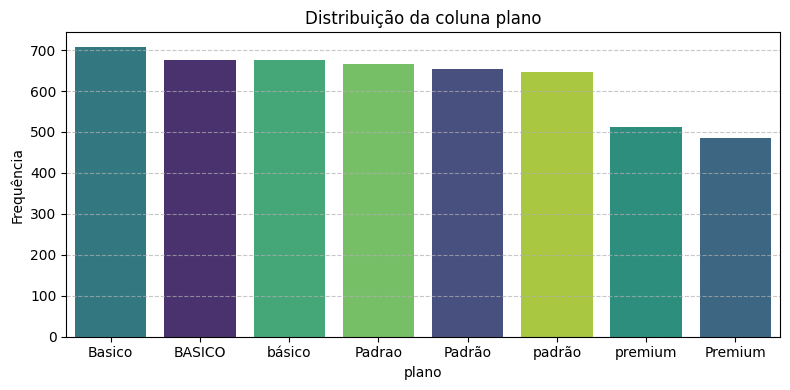

--------------------------------------------------
=== Coluna: ciclo ===
ciclo
Mensal    3794
Anual     1231
Name: count, dtype: int64




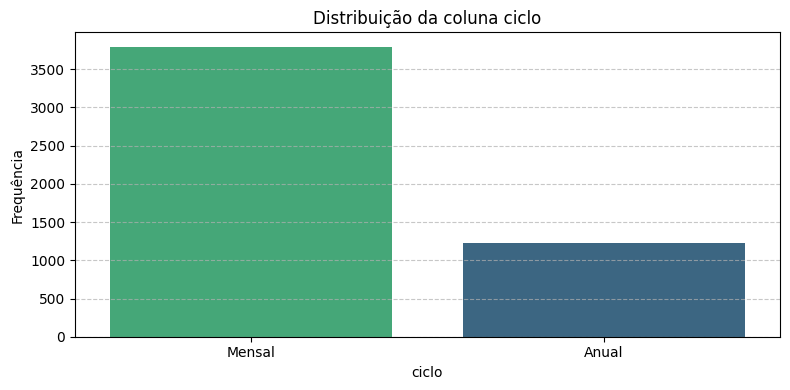

--------------------------------------------------
=== Coluna: regiao ===
regiao
Sudeste         2057
Nordeste         964
Sul              938
Centro-Oeste     488
Norte            408
?                170
Name: count, dtype: int64




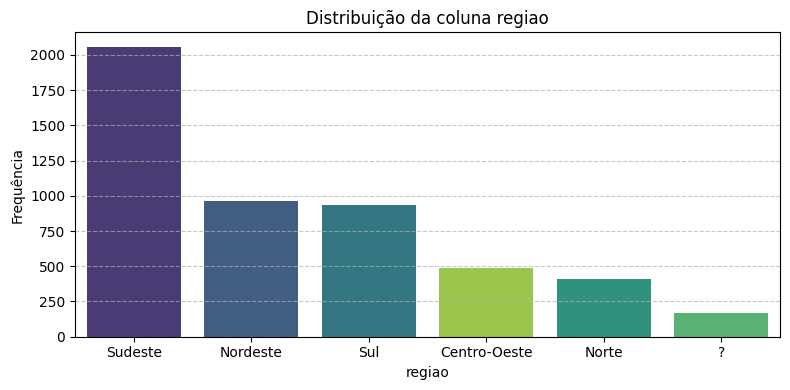

--------------------------------------------------
=== Coluna: canal_aquisicao ===
canal_aquisicao
Organico     781
orgânico     729
Indicacao    556
IG           529
indicação    526
Instagram    519
instagram    499
Google       452
google       434
Name: count, dtype: int64




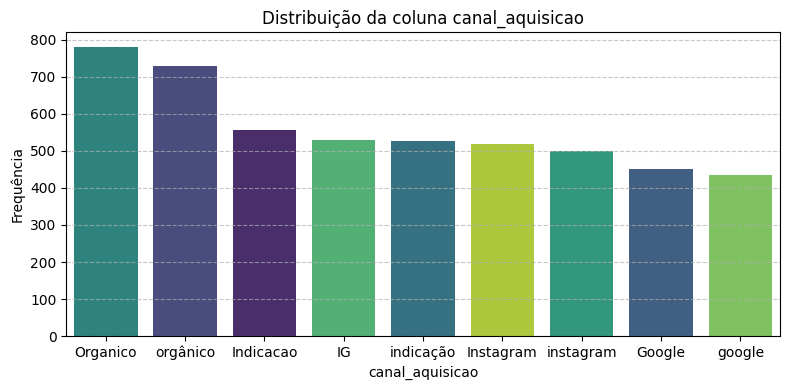

--------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

colunas_categoricas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

for col in colunas_categoricas:
    if col in df.columns:
        # Exibir contagens e valores únicos
        print(f"=== Coluna: {col} ===")
        contagens = df[col].value_counts()
        print(contagens)
        print("\n")

        # Criar o gráfico de barras
        plt.figure(figsize=(8, 4))
        sns.countplot(data=df, x=col, order=contagens.index, palette='viridis', hue=col, legend=False)
        plt.title(f'Distribuição da coluna {col}')
        plt.xlabel(col)
        plt.ylabel('Frequência')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
        print("-" * 50)
    else:
        print(f"Coluna '{col}' não encontrada no DataFrame.\n")

### Análise de Nulos e Limpeza de Dados

In [ ]:
# 1. Quantidade de nulos por coluna
print("=== 1. Quantidade de Nulos por Coluna ===")
print(df.isnull().sum())
print("\n" + "="*50 + "\n")

# 2. Exemplo do dataframe onde regiao é '?'
print("=== 2. Exemplo de linhas com regiao = '?' ===")
df_regiao_interrogacao = df[df['regiao'] == '?']
display(df_regiao_interrogacao.head())
print("\n" + "="*50 + "\n")

=== 1. Quantidade de Nulos por Coluna ===
cliente_id                   0
idade                        0
plano                        0
ciclo                        0
valor_mensal                 0
regiao                       0
canal_aquisicao              0
nps                          0
data_assinatura              0
data_cancelamento         3509
data_ultimo_acesso          50
data_extracao                0
dias_ativos_ult_mes          0
horas_assistidas_total       0
motivo_cancelamento       3509
churn                        0
dtype: int64


=== 2. Exemplo de linhas com regiao = '?' ===


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0


In [ ]:
# 3. Padronização da coluna 'plano'
# Basico, BASICO -> básico
# Padrao, Padrão -> padrão
# Premium -> premium
df['plano'] = df['plano'].replace({
    'Basico': 'básico',
    'BASICO': 'básico',
    'Padrao': 'padrão',
    'Padrão': 'padrão',
    'Premium': 'premium'
})

# 4. Padronização da coluna 'canal_aquisicao'
# Organico -> orgânico
# Indicacao ou Indicação ou variantes -> indicação
# IG, Instagram -> instagram
# Google -> google
df['canal_aquisicao'] = df['canal_aquisicao'].replace({
    'Organico': 'orgânico',
    'Indicacao': 'indicação',
    'indicação': 'indicação',
    'Indicacão': 'indicação',
    'IG': 'instagram',
    'Instagram': 'instagram',
    'Google': 'google'
})

print("=== Colunas 'plano' e 'canal_aquisicao' padronizadas! ===")
print("\nNovas contagens para 'plano':")
print(df['plano'].value_counts())
print("\nNovas contagens para 'canal_aquisicao':")
print(df['canal_aquisicao'].value_counts())

=== Colunas 'plano' e 'canal_aquisicao' padronizadas! ===

Novas contagens para 'plano':
plano
básico     2062
padrão     1965
premium     998
Name: count, dtype: int64

Novas contagens para 'canal_aquisicao':
canal_aquisicao
instagram    1547
orgânico     1510
indicação    1082
google        886
Name: count, dtype: int64


### Tratamento de Valores '?'

In [ ]:
import numpy as np

# Substituindo todos os valores '?' por NaN (nulo)
df = df.replace('?', np.nan)

# Exibindo a nova contagem de nulos para verificar a substituição
print("=== Nova Contagem de Valores Nulos por Coluna ===")
print(df.isnull().sum())

=== Nova Contagem de Valores Nulos por Coluna ===
cliente_id                   0
idade                        0
plano                        0
ciclo                        0
valor_mensal                 0
regiao                     170
canal_aquisicao              0
nps                          0
data_assinatura              0
data_cancelamento         3509
data_ultimo_acesso          50
data_extracao                0
dias_ativos_ult_mes          0
horas_assistidas_total       0
motivo_cancelamento       3509
churn                        0
dtype: int64


### Conversão de Colunas de Data para Datetime

In [ ]:
# Identificando as colunas de data
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Convertendo cada uma das colunas para datetime
for col in colunas_data:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# Verificando os novos tipos das colunas
print("=== Tipos de dados atualizados ===")
print(df[colunas_data].dtypes)

=== Tipos de dados atualizados ===
data_assinatura       datetime64[ns]
data_cancelamento     datetime64[ns]
data_ultimo_acesso    datetime64[ns]
data_extracao         datetime64[ns]
dtype: object


### Criação de Colunas de Diferença de Datas

In [ ]:
from itertools import combinations

# Identificar todas as colunas datetime no DataFrame
datetime_cols = df.select_dtypes(include=['datetime64[ns]']).columns.tolist()

print("Colunas datetime identificadas:", datetime_cols)

# Gerar pares únicos de colunas datetime
date_pairs = list(combinations(datetime_cols, 2))

# Calcular a diferença entre as datas para cada par
for col1, col2 in date_pairs:
    new_col_name = f'diff_{col1}__{col2}'
    # Calcula a diferença em dias e converte para número inteiro (pode ter NaN)
    df[new_col_name] = (df[col2] - df[col1]).dt.days
    print(f"Coluna '{new_col_name}' criada.")

print('\nDataFrame com as novas colunas de diferença de datas (primeiras 5 linhas):')
display(df.head())

print('\nDataFrame Info (novas colunas de diferença de datas):')
df.info()

Colunas datetime identificadas: ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']
Coluna 'diff_data_assinatura__data_cancelamento' criada.
Coluna 'diff_data_assinatura__data_ultimo_acesso' criada.
Coluna 'diff_data_assinatura__data_extracao' criada.
Coluna 'diff_data_cancelamento__data_ultimo_acesso' criada.
Coluna 'diff_data_cancelamento__data_extracao' criada.
Coluna 'diff_data_ultimo_acesso__data_extracao' criada.

DataFrame com as novas colunas de diferença de datas (primeiras 5 linhas):


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,15,276.0,NaN,0,NaN,293.0,295,NaN,NaN,2.0
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,14,394.9,NaN,0,NaN,607.0,608,NaN,NaN,1.0
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,5,257.0,PREÇO,1,607.0,590.0,1047,-17.0,440.0,457.0
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,286.0,304,NaN,NaN,18.0
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,11,205.3,NaN,0,NaN,270.0,285,NaN,NaN,15.0



DataFrame Info (novas colunas de diferença de datas):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 22 columns):
 #   Column                                      Non-Null Count  Dtype         
---  ------                                      --------------  -----         
 0   cliente_id                                  5025 non-null   int64         
 1   idade                                       5025 non-null   int64         
 2   plano                                       5025 non-null   object        
 3   ciclo                                       5025 non-null   object        
 4   valor_mensal                                5025 non-null   float64       
 5   regiao                                      4855 non-null   object        
 6   canal_aquisicao                             5025 non-null   object        
 7   nps                                         5025 non-null   int64         
 8   data_assinatura                  

### Sanity Check nas Colunas de Diferença de Datas

In [ ]:
# 1. Estatísticas descritivas das novas colunas de diferença de data
print("=== Estatísticas Descritivas (Sanity Check) ===")
display(df[colunas_novas].describe())

# 2. Verificação rápida para garantir que não há valores negativos (o que seria impossível já que usamos .abs())
print("\n=== Verificação de Valores Negativos ===")
valores_negativos = (df[colunas_novas] < 0).sum()
print(valores_negativos)

# 3. Exemplo de algumas linhas contendo os valores calculados e as datas originais para validação visual
print("\n=== Amostra de Validação Visual ===")
display(df[colunas_data + colunas_novas].dropna().head())

=== Estatísticas Descritivas (Sanity Check) ===


,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao
count,1516.000000,4975.000000,5025.000000,1501.000000,1516.000000,4975.000000
mean,220.407652,372.186533,412.432040,-21.000666,79.694591,40.451859
std,145.004268,277.107592,270.382969,10.783104,67.851077,55.107192
min,11.000000,-47.000000,1.000000,-137.000000,3.000000,0.000000
25%,118.000000,163.000000,213.000000,-30.000000,30.000000,10.000000
50%,182.500000,307.000000,349.000000,-21.000000,60.500000,20.000000
75%,288.500000,512.000000,549.000000,-12.000000,107.250000,44.000000
max,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000



=== Verificação de Valores Negativos ===
diff_data_assinatura__data_cancelamento          0
diff_data_assinatura__data_ultimo_acesso         1
diff_data_assinatura__data_extracao              0
diff_data_cancelamento__data_ultimo_acesso    1501
diff_data_cancelamento__data_extracao            0
diff_data_ultimo_acesso__data_extracao           0
dtype: int64

=== Amostra de Validação Visual ===


,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,607.0,590.0,1047,-17.0,440.0,457.0
6,2023-10-12,2023-12-28,2023-12-09,2024-01-31,77.0,58.0,111,-19.0,34.0,53.0
8,2023-04-26,2023-12-17,2023-12-07,2024-01-31,235.0,225.0,280,-10.0,45.0,55.0
11,2023-08-18,2023-11-16,2023-07-02,2024-01-31,90.0,-47.0,166,-137.0,76.0,213.0
17,2022-04-16,2023-04-15,2023-03-29,2024-01-31,364.0,347.0,655,-17.0,291.0,308.0


In [ ]:
# Filtrar o DataFrame para remover linhas onde 'diff_data_assinatura__data_ultimo_acesso' é negativo
initial_rows = len(df)
df = df[df['diff_data_assinatura__data_ultimo_acesso'].isnull() | (df['diff_data_assinatura__data_ultimo_acesso'] >= 0)]
final_rows = len(df)

print(f"Linhas antes do filtro: {initial_rows}")
print(f"Linhas após o filtro: {final_rows}")
print(f"Foram removidas {initial_rows - final_rows} linhas com 'diff_data_assinatura__data_ultimo_acesso' negativo.")

Linhas antes do filtro: 5025
Linhas após o filtro: 5024
Foram removidas 1 linhas com 'diff_data_assinatura__data_ultimo_acesso' negativo.


### Verificação após o filtro

In [ ]:
# 1. Identificando as colunas numéricas originais e criadas
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("=== Colunas Numéricas Identificadas ===")
print(colunas_numericas)
print("\n" + "="*50 + "\n")

# 2. Exibindo a contagem de valores nulos apenas para as colunas numéricas
print("=== Quantidade de Nulos nas Colunas Numéricas ===")
nulos_numericas = df[colunas_numericas].isnull().sum()
display(nulos_numericas.to_frame(name='Quantidade de Nulos'))
print("\n" + "="*50 + "\n")

# 3. Estatísticas descritivas das colunas numéricas
print("=== Estatísticas Descritivas das Colunas Numéricas ===")
display(df[colunas_numericas].describe())

=== Colunas Numéricas Identificadas ===
['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'diff_data_assinatura__data_cancelamento', 'diff_data_assinatura__data_ultimo_acesso', 'diff_data_assinatura__data_extracao', 'diff_data_cancelamento__data_ultimo_acesso', 'diff_data_cancelamento__data_extracao', 'diff_data_ultimo_acesso__data_extracao']


=== Quantidade de Nulos nas Colunas Numéricas ===


,Quantidade de Nulos
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
diff_data_assinatura__data_cancelamento,3509
diff_data_assinatura__data_ultimo_acesso,50
diff_data_assinatura__data_extracao,0




=== Estatísticas Descritivas das Colunas Numéricas ===


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao
count,5024.000000,5024.000000,5024.000000,5024.000000,5024.000000,5024.000000,5024.000000,1515.000000,4974.000000,5024.000000,1500.000000,1515.000000,4974.000000
mean,3497.606688,36.326831,416.155633,6.410032,10.655454,281.909514,0.301553,220.493729,372.270808,412.481091,-20.923333,79.697030,40.417169
std,1443.289344,11.678633,1128.049703,2.435279,5.999446,254.705024,0.458978,145.013398,277.071683,270.387522,10.361967,67.873415,55.058380
min,1000.000000,-2.000000,19.900000,0.000000,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000,-39.000000,3.000000,0.000000
25%,2247.750000,29.000000,19.900000,5.000000,5.000000,65.475000,0.000000,118.000000,163.000000,213.000000,-30.000000,30.000000,10.000000
50%,3496.500000,36.000000,34.900000,7.000000,12.000000,208.700000,0.000000,183.000000,307.000000,349.000000,-21.000000,60.000000,20.000000
75%,4747.250000,44.000000,55.900000,8.000000,15.000000,427.750000,1.000000,289.000000,512.000000,549.250000,-12.000000,107.500000,44.000000
max,5999.000000,300.000000,5590.000000,10.000000,28.000000,900.000000,1.000000,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000


In [ ]:
df.isnull().sum()

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [ ]:
df_filtrado = df.copy()

## Colunas numéricas

In [ ]:
df_filtrado.describe()

,cliente_id,idade,valor_mensal,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,churn,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao
count,5024.000000,5024.000000,5024.000000,5024.000000,5024,1515,4974,5024,5024.000000,5024.000000,5024.000000,1515.000000,4974.000000,5024.000000,1500.000000,1515.000000,4974.000000
mean,3497.606688,36.326831,416.155633,6.410032,2022-12-14 12:27:13.757961728,2023-11-12 07:16:16.633663232,2023-12-21 13:59:16.574185472,2024-01-31 00:00:00,10.655454,281.909514,0.301553,220.493729,372.270808,412.481091,-20.923333,79.697030,40.417169
min,1000.000000,-2.000000,19.900000,0.000000,2019-02-11 00:00:00,2022-11-17 00:00:00,2022-10-19 00:00:00,2024-01-31 00:00:00,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000,-39.000000,3.000000,0.000000
25%,2247.750000,29.000000,19.900000,5.000000,2022-07-30 18:00:00,2023-10-15 12:00:00,2023-12-18 00:00:00,2024-01-31 00:00:00,5.000000,65.475000,0.000000,118.000000,163.000000,213.000000,-30.000000,30.000000,10.000000
50%,3496.500000,36.000000,34.900000,7.000000,2023-02-16 00:00:00,2023-12-02 00:00:00,2024-01-11 00:00:00,2024-01-31 00:00:00,12.000000,208.700000,0.000000,183.000000,307.000000,349.000000,-21.000000,60.000000,20.000000
75%,4747.250000,44.000000,55.900000,8.000000,2023-07-02 00:00:00,2024-01-01 00:00:00,2024-01-21 00:00:00,2024-01-31 00:00:00,15.000000,427.750000,1.000000,289.000000,512.000000,549.250000,-12.000000,107.500000,44.000000
max,5999.000000,300.000000,5590.000000,10.000000,2024-01-30 00:00:00,2024-01-28 00:00:00,2024-01-31 00:00:00,2024-01-31 00:00:00,28.000000,900.000000,1.000000,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000
std,1443.289344,11.678633,1128.049703,2.435279,NaN,NaN,NaN,NaN,5.999446,254.705024,0.458978,145.013398,277.071683,270.387522,10.361967,67.873415,55.058380


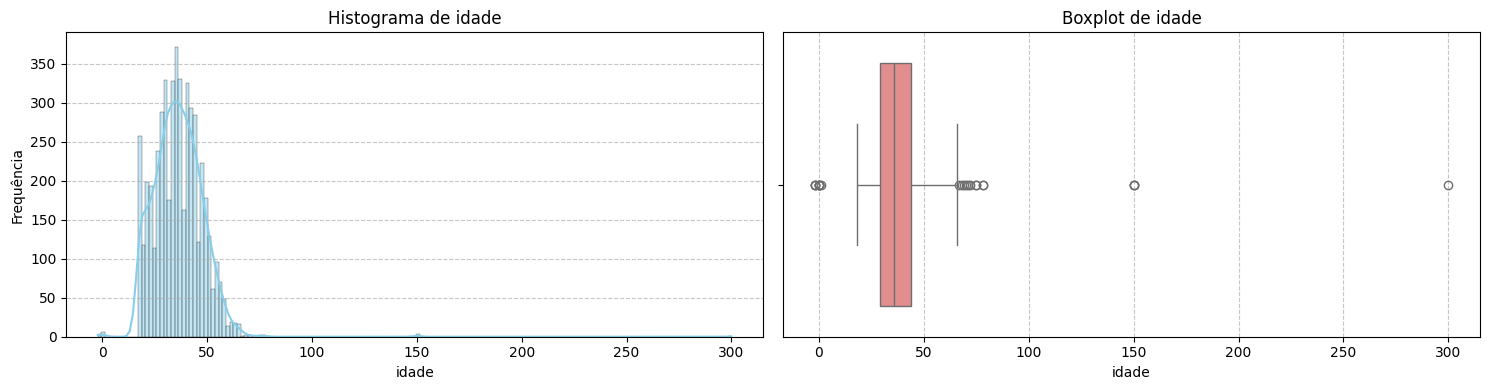

--------------------------------------------------------------------------------


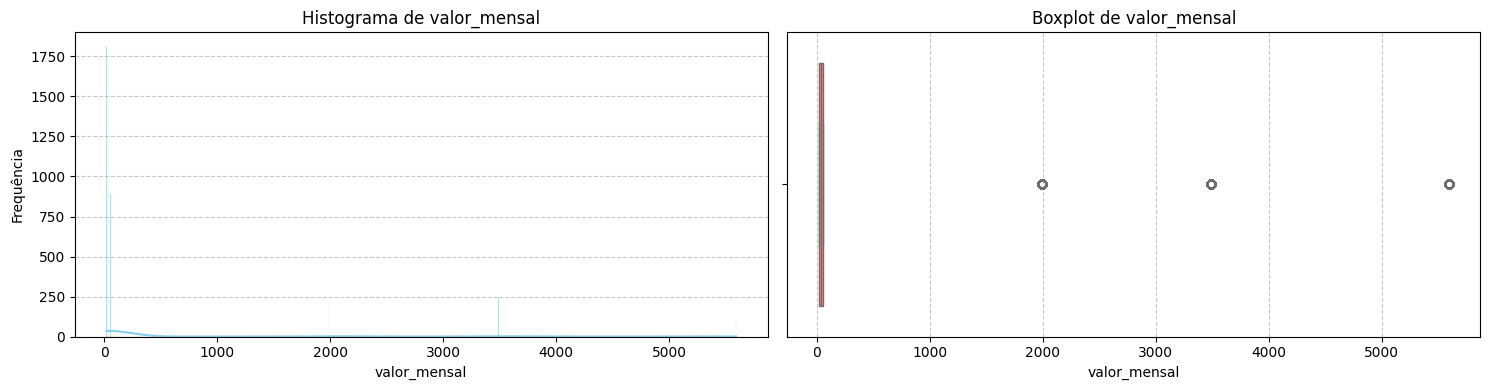

--------------------------------------------------------------------------------


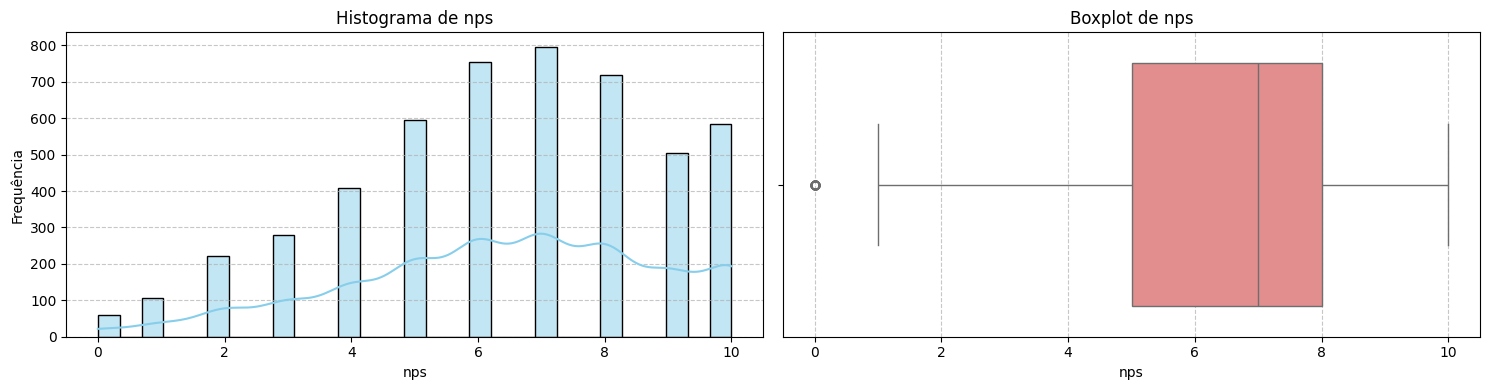

--------------------------------------------------------------------------------


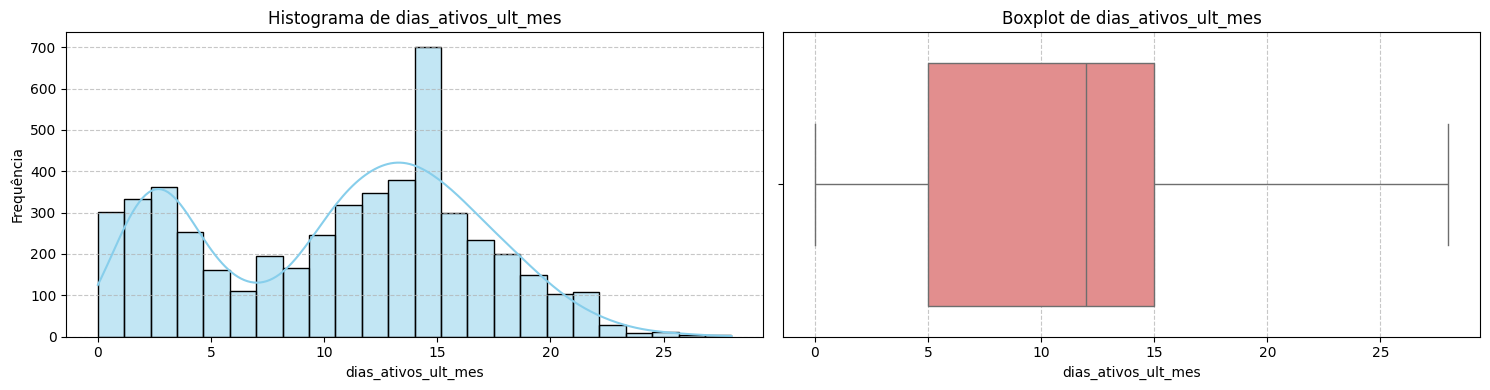

--------------------------------------------------------------------------------


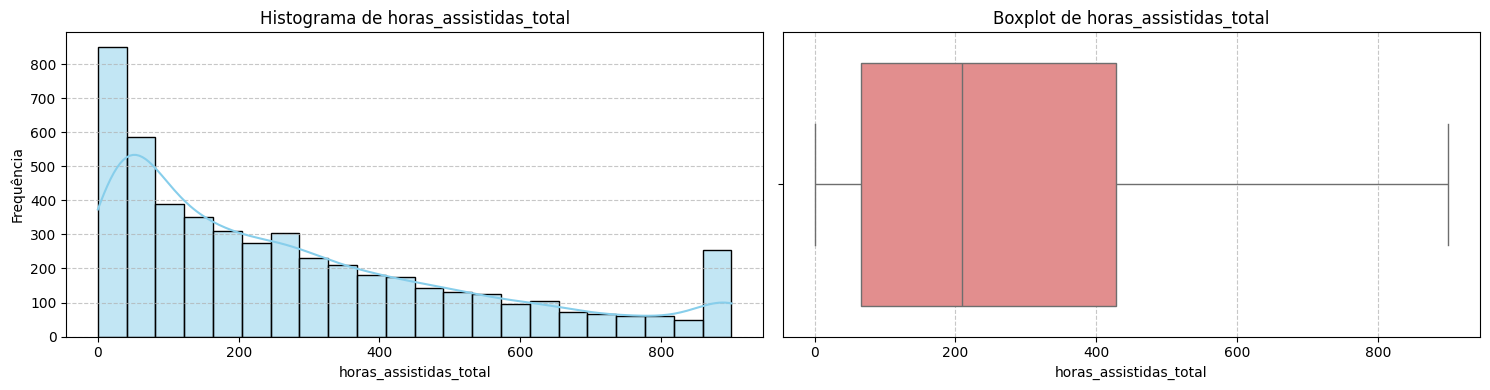

--------------------------------------------------------------------------------


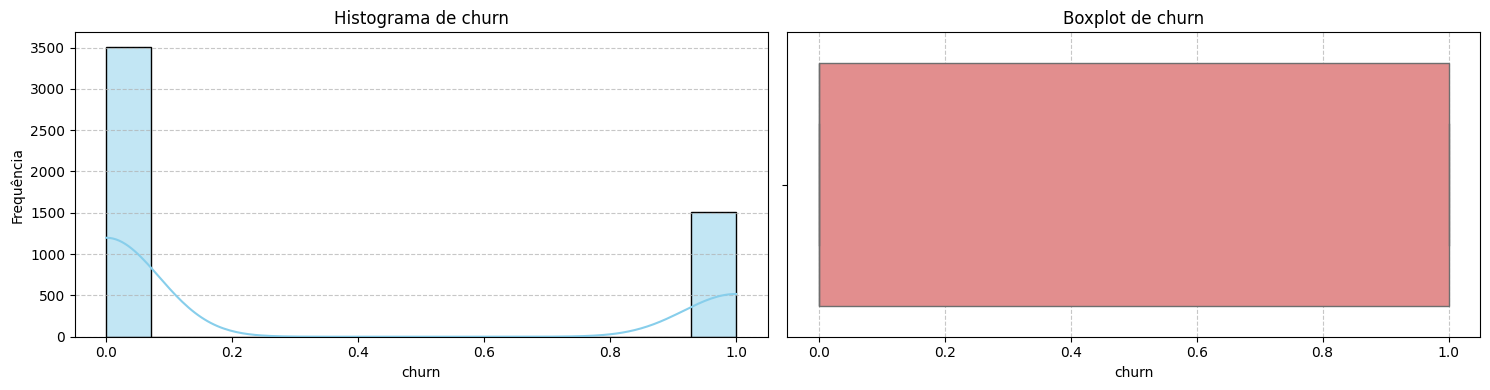

--------------------------------------------------------------------------------


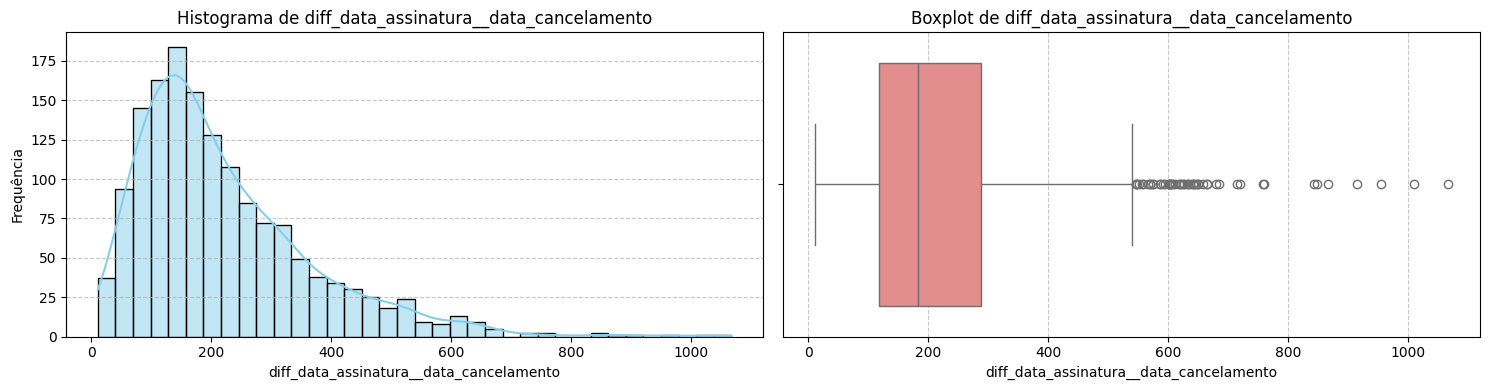

--------------------------------------------------------------------------------


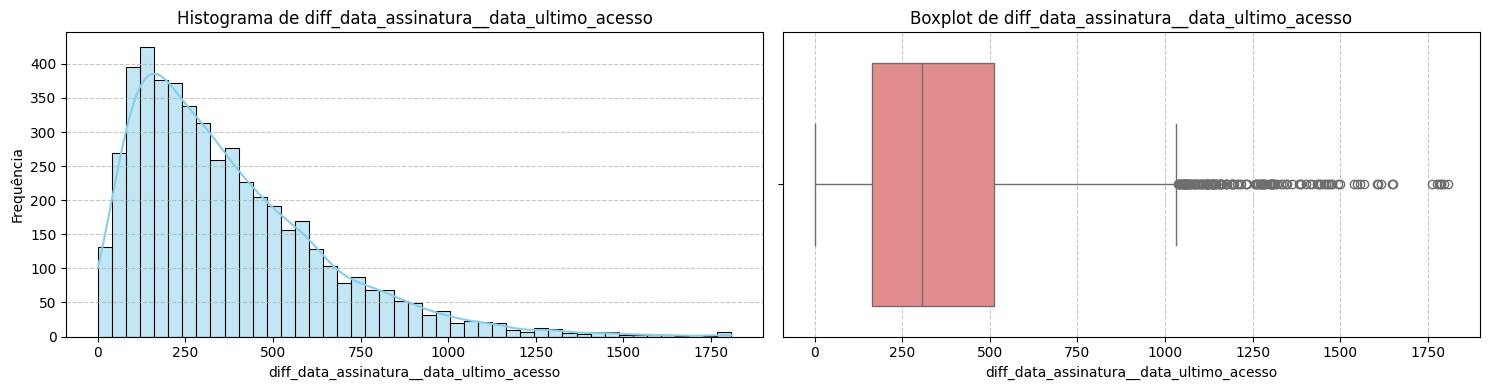

--------------------------------------------------------------------------------


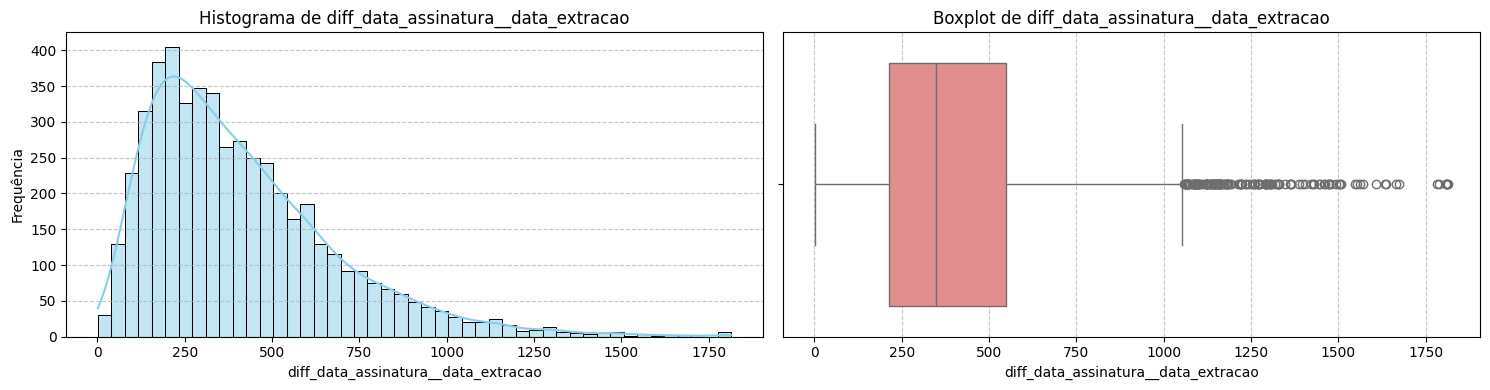

--------------------------------------------------------------------------------


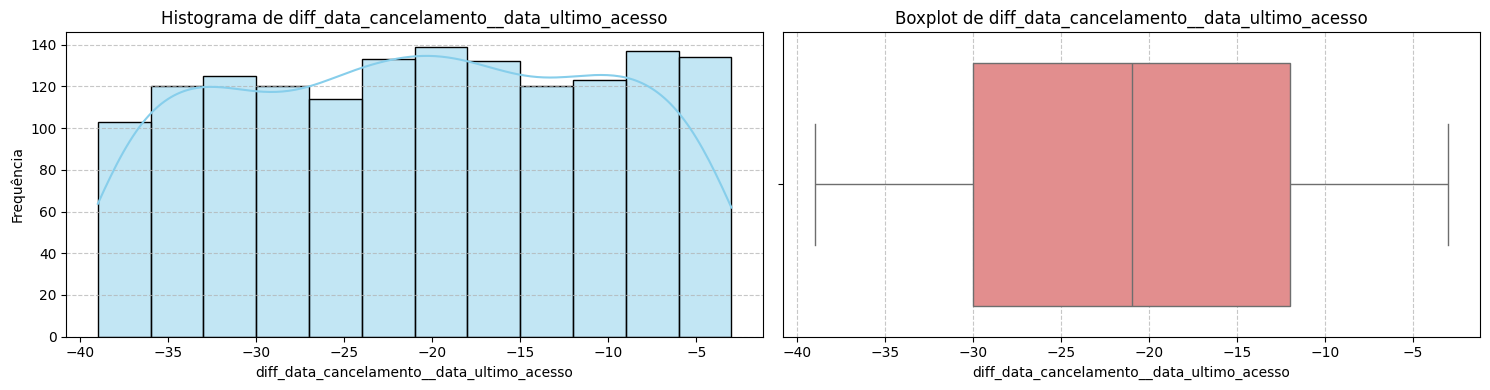

--------------------------------------------------------------------------------


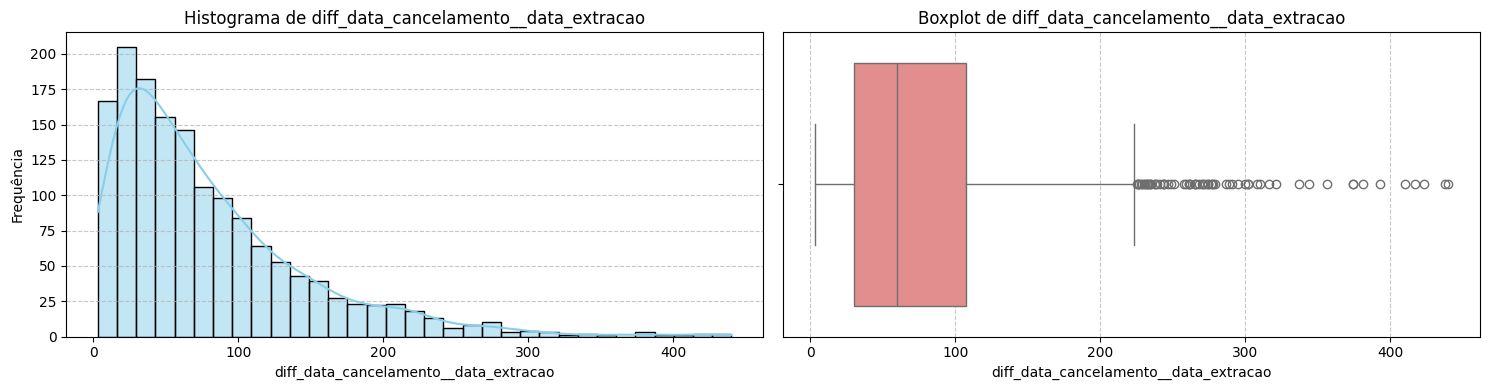

--------------------------------------------------------------------------------


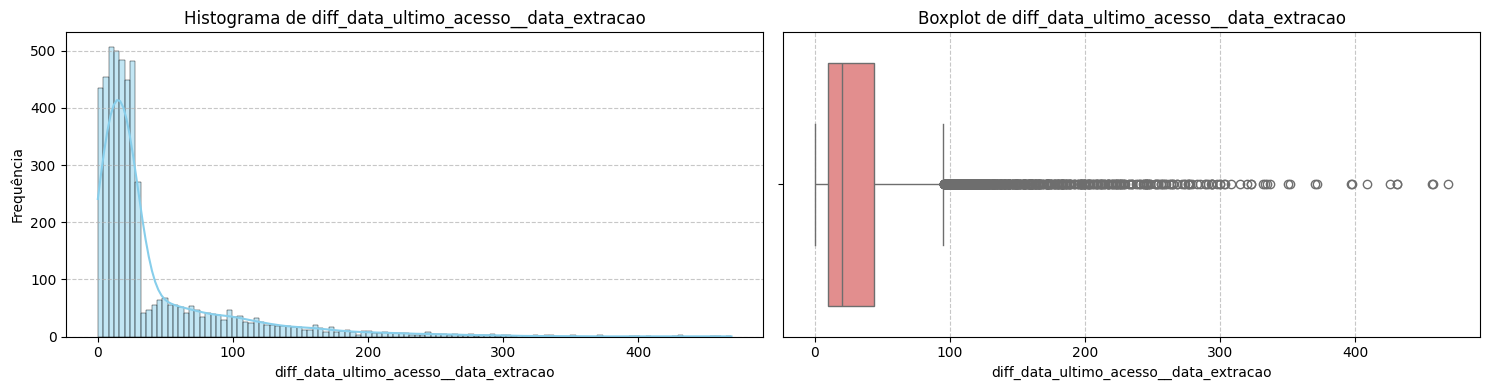

--------------------------------------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de colunas numéricas excluindo 'cliente_id'
cols_para_plotar = [col for col in colunas_numericas if col != 'cliente_id']

# Gerando os gráficos
for col in cols_para_plotar:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # Histograma
    sns.histplot(data=df_filtrado, x=col, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histograma de {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequência')
    axes[0].grid(axis='y', linestyle='--', alpha=0.7)

    # Boxplot
    sns.boxplot(data=df_filtrado, x=col, ax=axes[1], color='lightcoral')
    axes[1].set_title(f'Boxplot de {col}')
    axes[1].set_xlabel(col)
    axes[1].grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()
    print("-" * 80)

In [ ]:
# Guardando o número de linhas anterior
linhas_antes = df_filtrado.shape[0]

# Filtrando para manter idades entre 18 e 90 anos (inclusive)
df_filtrado = df_filtrado[(df_filtrado['idade'] >= 18) & (df_filtrado['idade'] <= 90)]

linhas_depois = df_filtrado.shape[0]

print(f"Quantidade de registros ANTES do filtro de idade: {linhas_antes}")
print(f"Quantidade de registros DEPOIS do filtro de idade: {linhas_depois}")
print(f"Linhas removidas (idades fora do intervalo 18-90): {linhas_antes - linhas_depois}")

print("\nPrimeiras 5 linhas do DataFrame df_filtrado após o filtro de idade:")
display(df_filtrado.head())

Quantidade de registros ANTES do filtro de idade: 5024
Quantidade de registros DEPOIS do filtro de idade: 5011
Linhas removidas (idades fora do intervalo 18-90): 13

Primeiras 5 linhas do DataFrame df_filtrado após o filtro de idade:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,15,276.0,NaN,0,NaN,293.0,295,NaN,NaN,2.0
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,14,394.9,NaN,0,NaN,607.0,608,NaN,NaN,1.0
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,5,257.0,PREÇO,1,607.0,590.0,1047,-17.0,440.0,457.0
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,286.0,304,NaN,NaN,18.0
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,11,205.3,NaN,0,NaN,270.0,285,NaN,NaN,15.0


In [ ]:
# Filtrando e exibindo as linhas onde o valor_mensal é maior do que 1000
df_valor_alto = df_filtrado[df_filtrado['valor_mensal'] > 1000]

print(f"Quantidade de registros com valor mensal > 1000: {df_valor_alto.shape[0]}")
display(df_valor_alto)

Quantidade de registros com valor mensal > 1000: 602


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,286.0,304,NaN,NaN,18.0
14,5581,18,padrão,Mensal,3490.0,Sudeste,orgânico,7,2023-07-22,NaT,...,15,160.7,NaN,0,NaN,189.0,193,NaN,NaN,4.0
29,5979,31,padrão,Mensal,3490.0,Sudeste,instagram,10,2023-08-22,NaT,...,14,117.2,NaN,0,NaN,134.0,162,NaN,NaN,28.0
34,1433,56,padrão,Anual,3490.0,NaN,orgânico,9,2023-04-14,NaT,...,11,180.4,NaN,0,NaN,283.0,292,NaN,NaN,9.0
42,4776,61,básico,Anual,1990.0,Sudeste,orgânico,4,2023-10-01,2023-12-15,...,6,47.8,problema tecnico,1,75.0,55.0,122,-20.0,47.0,67.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,padrão,Anual,3490.0,Sudeste,indicação,7,2020-12-01,NaT,...,20,900.0,NaN,0,NaN,1138.0,1156,NaN,NaN,18.0
4991,2396,23,padrão,Anual,3490.0,Nordeste,orgânico,8,2021-04-14,NaT,...,18,900.0,NaN,0,NaN,1017.0,1022,NaN,NaN,5.0
5000,5926,37,padrão,Anual,3490.0,Centro-Oeste,orgânico,10,2022-12-01,NaT,...,9,243.6,NaN,0,NaN,402.0,426,NaN,NaN,24.0
5006,4388,18,básico,Anual,1990.0,Nordeste,instagram,9,2023-05-03,NaT,...,11,160.6,NaN,0,NaN,251.0,273,NaN,NaN,22.0


In [ ]:
# Contando a quantidade de valores distintos na coluna 'valor_mensal'
valores_distintos = df_filtrado['valor_mensal'].value_counts(dropna=False)

print(f"Quantidade de valores distintos: {len(valores_distintos)}")
print("\nFrequência de cada valor distinto:")
display(valores_distintos.to_frame(name='Frequência'))

Quantidade de valores distintos: 6

Frequência de cada valor distinto:


,Frequência
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104


In [ ]:
# Dividindo por 100 os valores acima de 1900 na coluna valor_mensal
df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] = df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] / 100

# Exibindo os novos valores distintos e suas frequências para validar a alteração
print("=== Valores Distintos Atualizados na Coluna valor_mensal ===")
valores_distintos_atualizados = df_filtrado['valor_mensal'].value_counts(dropna=False)
display(valores_distintos_atualizados.to_frame(name='Nova Frequência'))

=== Valores Distintos Atualizados na Coluna valor_mensal ===


,Nova Frequência
valor_mensal,
19.9,2058
34.9,1958
55.9,995


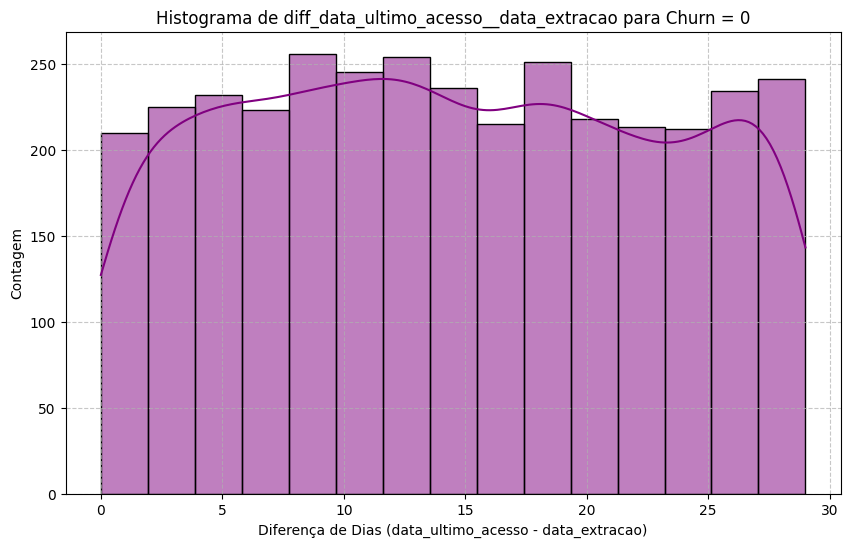

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar o DataFrame para churn == 0
df_churn_0 = df_filtrado[df_filtrado['churn'] == 0]

# Criar o histograma para 'diff_data_ultimo_acesso__data_extracao' onde churn é 0
plt.figure(figsize=(10, 6))
sns.histplot(df_churn_0['diff_data_ultimo_acesso__data_extracao'].dropna(), kde=True, color='purple')
plt.title('Histograma de diff_data_ultimo_acesso__data_extracao para Churn = 0')
plt.xlabel('Diferença de Dias (data_ultimo_acesso - data_extracao)')
plt.ylabel('Contagem')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Criando novas variáveis

"crie novas colunas de acordo com as regras abaixo

1) recencia = diff_data_ultimo_acesso__data_extracao

2) meses_assinatura = diff_data_assinatur__data_cancelamento/30 se data_cancelamento for nula (cliente ativo), use (data_assinatura - data_extracao)/30 no lugar;

3) receita_acumulada = valor_mensal multiplicado por meses_assinatura"

In [ ]:
import numpy as np

# 1. Criando a variável 'recencia'
# Diferença em dias entre o último acesso e a data de extração
df_filtrado['recencia'] = (df_filtrado['data_extracao'] - df_filtrado['data_ultimo_acesso']).dt.days

# 2. Criando a variável 'meses_assinatura'
# Se data_cancelamento for nula, usamos data_extracao. Caso contrário, usamos data_cancelamento.
data_final = df_filtrado['data_cancelamento'].fillna(df_filtrado['data_extracao'])
df_filtrado['meses_assinatura'] = (data_final - df_filtrado['data_assinatura']).dt.days / 30.0

# 3. Criando a variável 'receita_acumulada'
df_filtrado['receita_acumulada'] = df_filtrado['valor_mensal'] * df_filtrado['meses_assinatura']

# Exibindo uma amostra do DataFrame para validar as novas colunas
colunas_validacao = [
    'data_assinatura', 'data_cancelamento', 'data_ultimo_acesso',
    'data_extracao', 'recencia', 'meses_assinatura', 'valor_mensal', 'receita_acumulada'
]

print("=== Amostra das Novas Variáveis Criadas ===")
display(df_filtrado[colunas_validacao].head(10))

print("Informações das Novas Variáveis:")
display(df_filtrado[['recencia', 'meses_assinatura', 'receita_acumulada']].info())

print("\n=== Estatísticas Descritivas das Novas Variáveis ===")
display(df_filtrado[['recencia', 'meses_assinatura', 'receita_acumulada']].describe())

=== Amostra das Novas Variáveis Criadas ===


,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,recencia,meses_assinatura,valor_mensal,receita_acumulada
0,2023-04-11,NaT,2024-01-29,2024-01-31,2.0,9.833333,19.9,195.683333
1,2022-06-02,NaT,2024-01-30,2024-01-31,1.0,20.266667,34.9,707.306667
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,457.0,20.233333,55.9,1131.043333
3,2023-04-02,NaT,2024-01-13,2024-01-31,18.0,10.133333,19.9,201.653333
4,2023-04-21,NaT,2024-01-16,2024-01-31,15.0,9.500000,19.9,189.050000
5,2022-11-22,NaT,2024-01-20,2024-01-31,11.0,14.500000,55.9,810.550000
6,2023-10-12,2023-12-28,2023-12-09,2024-01-31,53.0,2.566667,19.9,51.076667
7,2022-01-21,NaT,2024-01-12,2024-01-31,19.0,24.666667,34.9,860.866667
8,2023-04-26,2023-12-17,2023-12-07,2024-01-31,55.0,7.833333,19.9,155.883333
9,2023-10-07,NaT,2024-01-25,2024-01-31,6.0,3.866667,19.9,76.946667


Informações das Novas Variáveis:
<class 'pandas.core.frame.DataFrame'>
Index: 5011 entries, 0 to 5024
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   recencia           4961 non-null   float64
 1   meses_assinatura   5011 non-null   float64
 2   receita_acumulada  5011 non-null   float64
dtypes: float64(3)
memory usage: 156.6 KB


None


=== Estatísticas Descritivas das Novas Variáveis ===


,recencia,meses_assinatura,receita_acumulada
count,4961.000000,5011.000000,5011.000000
mean,40.452731,12.950376,428.914295
std,55.112223,9.186362,371.527653
min,0.000000,0.033333,0.663333
25%,10.000000,6.033333,168.585000
50%,20.000000,10.766667,321.080000
75%,44.000000,17.600000,570.033333
max,469.000000,60.500000,2893.756667


## Conclusões da univariada — variáveis categóricas

**1. Base suja**
- **`plano`**: "Basico" / "BASICO" / "básico" são o mesmo plano, mas contam separado (708 + 677 + 677). O mesmo com Padrão (3 formas) e Premium (2 formas). Sem unificar, você teria **8 planos** quando existem **3**.
- **`canal_aquisicao`**: pior ainda — 9 grafias para 4 canais. "Organico"/"orgânico", "Indicacao"/"indicação", "IG"/"Instagram"/"instagram", "Google"/"google".

**2. O `?` na região é ausente disfarçado** São **170 registros** com "?", que o `isnull()` não pega porque é texto. Representa ~3,4% da base sem região informada. Tratá-lo como categoria válida criaria uma "região Interrogação" nos gráficos; o certo foi convertê-lo em nulo.

**3. Insight de negócio real — a base é fortemente concentrada no Sudeste.** Somando as regiões válidas: **Sudeste (2.057) sozinho é ~42%** da base, mais que Nordeste (964) e Sul (938) juntos parciais. Norte (408) e Centro-Oeste (488) são pequenos. Isso importa para qualquer análise regional depois — há Sudeste de sobra para conclusões robustas, mas Norte tem amostra pequena, então taxa de churn dessa região terá muito mais incerteza.

**4. Insight de negócio — o produto é predominantemente mensal.** **Mensal (3.794) contra Anual (1.231)**: ~75% da base paga mês a mês.

**5. A distribuição dos canais é equilibrada — nenhum domina.** Depois de unificar: Orgânico (1.510), Instagram (1.547), Indicação (1.082), Google (
886). Aquisição diversificada, sem dependência perigosa de um único canal. Saudável do ponto de vista de risco de aquisição.


# Análise Bivariada

### Filtrar a base para evitar vieses

In [ ]:
df_analise = df_filtrado[
    (df_filtrado['diff_data_assinatura__data_extracao'] >= 220)
].copy()


print(f"Quantidade de registros em df_analise: {df_analise.shape[0]}")
display(df_analise.head())

Quantidade de registros em df_analise: 3668


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,churn,diff_data_assinatura__data_cancelamento,diff_data_assinatura__data_ultimo_acesso,diff_data_assinatura__data_extracao,diff_data_cancelamento__data_ultimo_acesso,diff_data_cancelamento__data_extracao,diff_data_ultimo_acesso__data_extracao,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,0,NaN,293.0,295,NaN,NaN,2.0,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,0,NaN,607.0,608,NaN,NaN,1.0,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,1,607.0,590.0,1047,-17.0,440.0,457.0,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,19.9,Sul,google,10,2023-04-02,NaT,...,0,NaN,286.0,304,NaN,NaN,18.0,18.0,10.133333,201.653333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,0,NaN,270.0,285,NaN,NaN,15.0,15.0,9.500000,189.050000


### Análise de Variáveis Categóricas vs. Churn (Crosstabs Normalizadas)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ajustando nomes das colunas com base no que foi calculado anteriormente
var_numericas = [
    'idade',
    'valor_mensal',
    'nps',
    'dias_ativos_ult_mes',
    'horas_assistidas_total',
    'dif_data_assinatura_vs_data_ultimo_acesso_dias', # Equivalente a diff_data_assinatura__data_ultimo_acesso
    'dif_data_assinatura_vs_data_extracao_dias',       # Equivalente a diff_data_assinatura__data_extracao
    'recencia',
    'meses_assinatura',
    'receita_acumulada'
]

var_categoricas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

print(f"Variáveis Numéricas para análise de Churn: {var_numericas}")
print(f"Variáveis Categóricas para análise de Churn: {var_categoricas}")

Variáveis Numéricas para análise de Churn: ['idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'dif_data_assinatura_vs_data_ultimo_acesso_dias', 'dif_data_assinatura_vs_data_extracao_dias', 'recencia', 'meses_assinatura', 'receita_acumulada']
Variáveis Categóricas para análise de Churn: ['plano', 'ciclo', 'regiao', 'canal_aquisicao']


In [ ]:
# --- Análise das Variáveis Categóricas ---
print("=== ANÁLISE DE VARIÁVEIS CATEGÓRICAS VS CHURN ===\n")
for var in var_categoricas:
    if var in df_analise.columns:
        print(f"\n--- Taxa de Churn por Categoria: {var} ---")
        # Calculando a taxa de churn por categoria
        tabela_churn = df_analise.groupby(var)['churn'].agg(['count', 'sum', 'mean'])
        tabela_churn.columns = ['Total Clientes', 'Quantidade Churn', 'Taxa Churn (%)']
        tabela_churn['Taxa Churn (%)'] = tabela_churn['Taxa Churn (%)'] * 100

        display(tabela_churn.sort_values(by='Taxa Churn (%)', ascending=False))
        print("="*80)
    else:
        print(f"Aviso: Coluna '{var}' não encontrada no DataFrame.")

=== ANÁLISE DE VARIÁVEIS CATEGÓRICAS VS CHURN ===


--- Taxa de Churn por Categoria: plano ---


,Total Clientes,Quantidade Churn,Taxa Churn (%)
plano,,,
básico,1486,404,27.187079
padrão,1436,325,22.632312
premium,746,159,21.313673



--- Taxa de Churn por Categoria: ciclo ---


,Total Clientes,Quantidade Churn,Taxa Churn (%)
ciclo,,,
Mensal,2752,668,24.273256
Anual,916,220,24.017467



--- Taxa de Churn por Categoria: regiao ---


,Total Clientes,Quantidade Churn,Taxa Churn (%)
regiao,,,
Centro-Oeste,353,93,26.345609
Norte,297,76,25.589226
Sul,707,174,24.611033
Nordeste,719,172,23.922114
Sudeste,1464,338,23.087432



--- Taxa de Churn por Categoria: canal_aquisicao ---


,Total Clientes,Quantidade Churn,Taxa Churn (%)
canal_aquisicao,,,
google,635,172,27.086614
instagram,1125,280,24.888889
orgânico,1111,255,22.952295
indicação,797,181,22.710163


### Análise de Variáveis Numéricas vs. Churn

**Média, 25º Percentil, Mediana e Desvio Padrão por Categoria de Churn**

=== ANÁLISE DE VARIÁVEIS NUMÉRICAS VS CHURN ===


--- Variável: idade ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,36.125540,10.633567,18.0,29.0,36.0,44.0,78.0
1,888.0,36.632883,10.600266,18.0,29.0,36.0,44.0,66.0


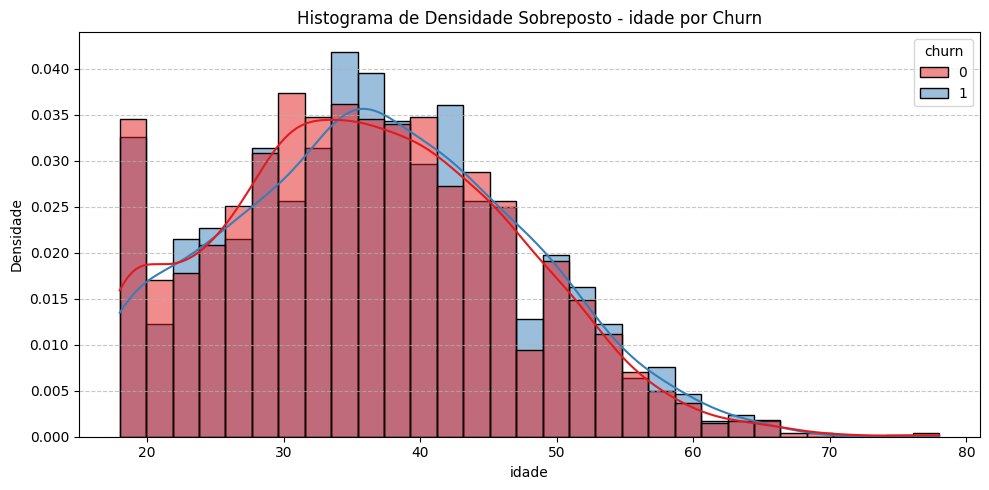


--- Variável: valor_mensal ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,33.496043,13.370968,19.9,19.9,34.9,34.9,55.9
1,888.0,31.835811,13.119920,19.9,19.9,34.9,34.9,55.9


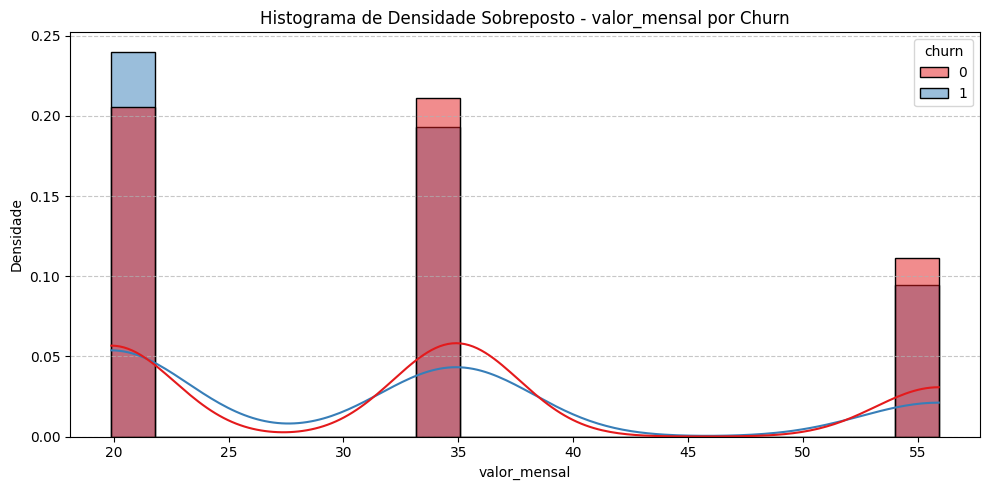


--- Variável: nps ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,7.376978,1.877014,1.0,6.0,7.0,9.0,10.0
1,888.0,4.090090,2.004165,0.0,3.0,4.0,6.0,8.0


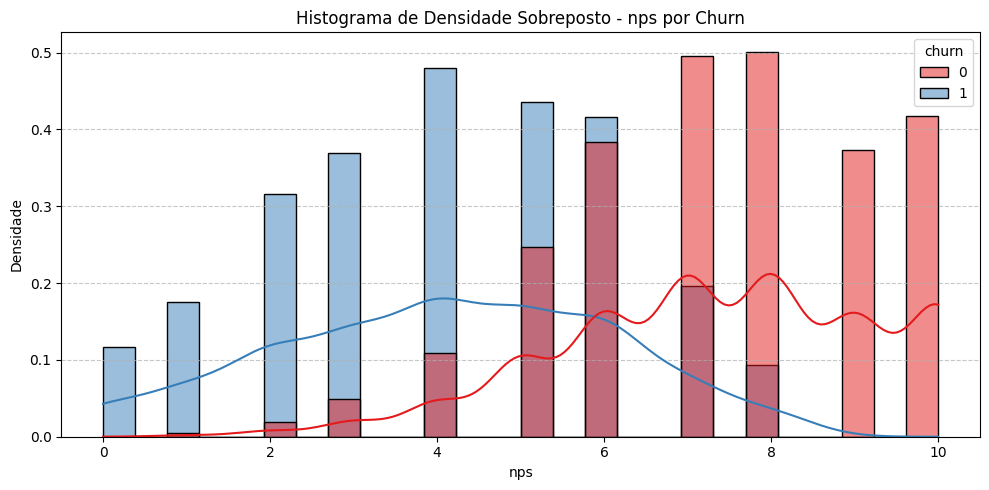


--- Variável: dias_ativos_ult_mes ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,13.995324,3.755046,3.0,11.0,14.0,16.0,28.0
1,888.0,2.967342,1.721950,0.0,2.0,3.0,4.0,11.0


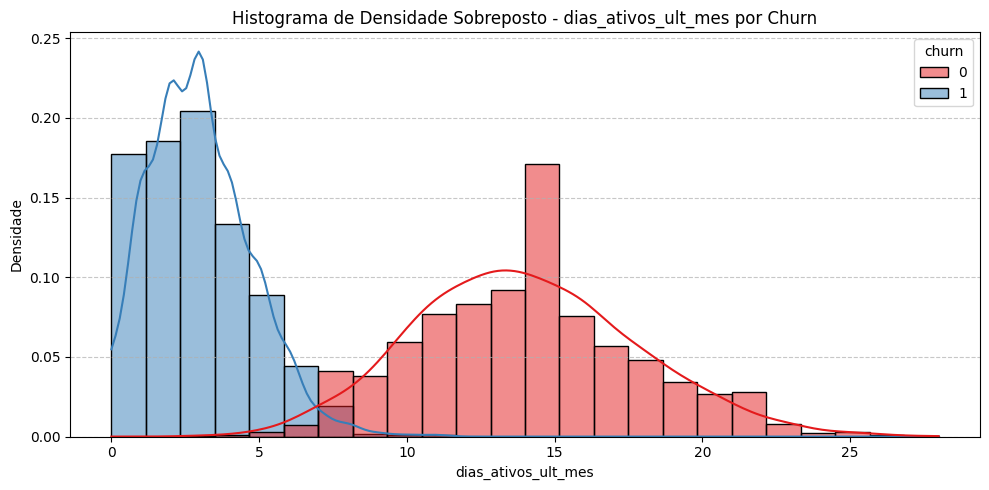


--- Variável: horas_assistidas_total ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,448.891475,226.739374,73.9,265.450,395.60,600.9,900.0
1,888.0,73.143131,55.191559,0.0,35.925,58.95,96.6,400.0


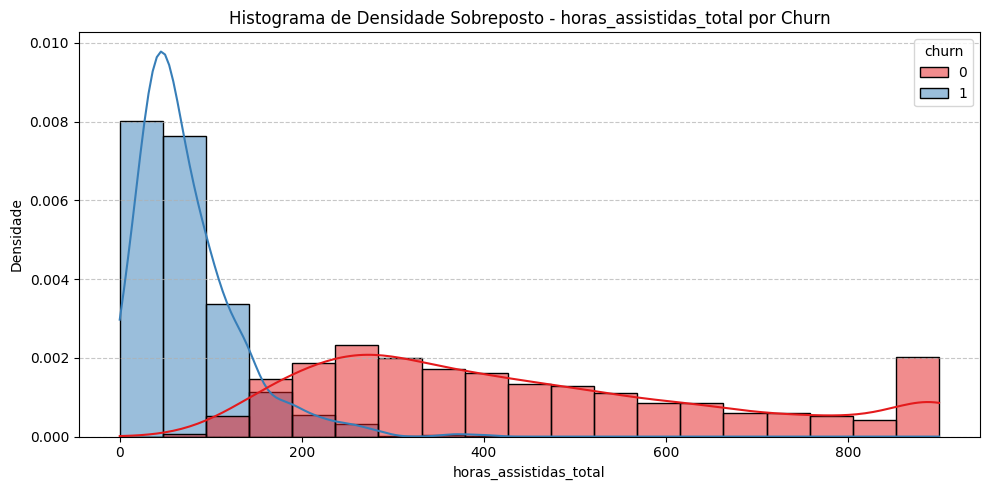

Aviso: Coluna 'dif_data_assinatura_vs_data_ultimo_acesso_dias' não encontrada no DataFrame.
Aviso: Coluna 'dif_data_assinatura_vs_data_extracao_dias' não encontrada no DataFrame.

--- Variável: recencia ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2755.0,14.603993,8.493044,0.0,8.00,14.0,22.0,29.0
1,878.0,130.011390,74.106997,13.0,75.25,117.0,165.0,469.0


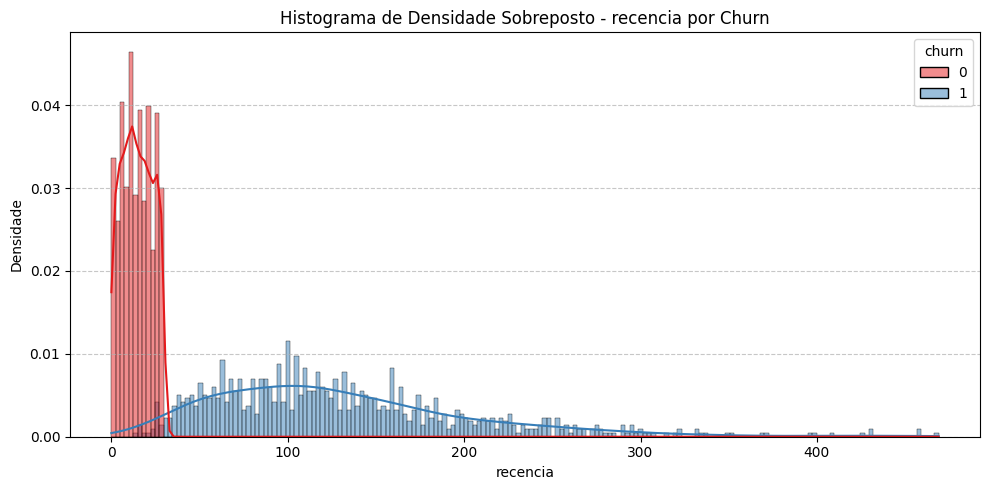


--- Variável: meses_assinatura ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,18.088873,8.848728,7.333333,11.366667,16.033333,22.441667,60.500000
1,888.0,10.006156,4.615595,3.800000,6.666667,8.900000,12.108333,35.566667


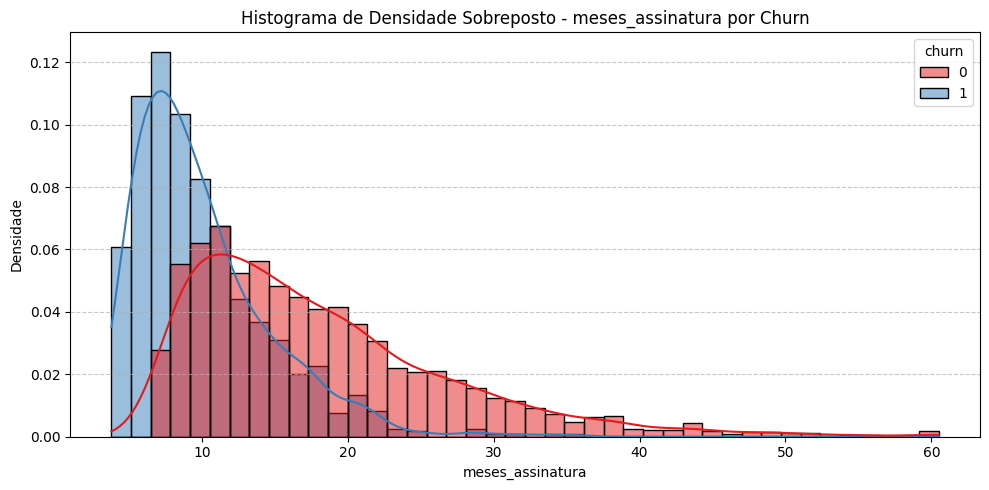


--- Variável: receita_acumulada ---


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,605.311556,396.917467,145.933333,329.013333,491.508333,762.103333,2893.756667
1,888.0,315.519917,195.137065,77.610000,172.173333,262.680000,392.043333,1341.600000


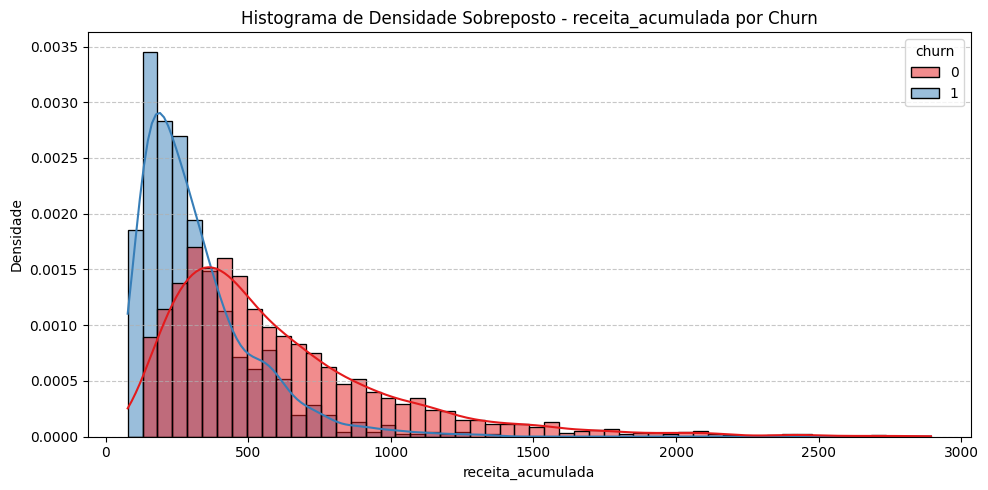

In [ ]:
# --- Análise das Variáveis Numéricas ---
print("=== ANÁLISE DE VARIÁVEIS NUMÉRICAS VS CHURN ===\n")
for var in var_numericas:
    if var in df_analise.columns:
        print(f"\n--- Variável: {var} ---")

        # Tabela de estatísticas por grupo de churn
        stats = df_analise.groupby('churn')[var].describe()
        display(stats)

        # Histograma de densidade sobreposto
        plt.figure(figsize=(10, 5))
        sns.histplot(data=df_analise, x=var, hue='churn', kde=True, stat='density', common_norm=False, palette='Set1', alpha=0.5)
        plt.title(f'Histograma de Densidade Sobreposto - {var} por Churn')
        plt.xlabel(var)
        plt.ylabel('Densidade')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
        print("="*80)
    else:
        print(f"Aviso: Coluna '{var}' não encontrada no DataFrame.")

### Cuidados importantes com conclusões precipitadas

**dias_ativos_ult_mes** —  Quem já deu churn não teve acesso nos últimos meses, então aparece zerado por definição — não porque usava pouco, mas porque já tinha saído.

**data_ultimo_acesso (e a recência derivada dela)** — Mesma contaminação. Para quem cancelou, o último acesso trava perto da data de saída, então a recência reflete o churn que já aconteceu, não um comportamento que o antecede. *Serve para descrever engajamento entre ativos, mas como preditor de churn é enganosa*

**horas_assistidas_total** — Viés parcial em 2 frentes. Primeiro, quem deu churn parou de assistir antes de sair, então *acumula menos horas naturalmente*, não é uma CAUSA do churn prévio.
Segundo, é confundida pelo *tempo de casa*: veterano naturalmente acumula mais horas — legal ser normalizada por `meses_assinatura` para comparar de forma justa

**meses_assinatura** —  entre os clientes maduros, quem permanece ativo tem mais tempo de casa acumulado do que quem cancelou, o que é esperado — cliente que não dá churn continua na base acumulando meses, enquanto o do churner congela no cancelamento. A leitura honesta é descritiva: os sobreviventes são, por natureza, mais antigos, e há um sinal real de que quem cancela tende a durar menos. Vale só a ressalva de não transformar isso diretamente numa regra preditiva ("abaixo de X meses = risco"), porque o tempo do churner está fechado e o do ativo ainda corre — a forma rigorosa de medir essa queda de permanência ao longo do tempo é a análise de cohort, que desdobra essa diferença agregada na curva de retenção mês a mês.

**tempo até o churn (data_cancelamento − data_assinatura)** — Só existe para quem deu churn (cancelamento é vazio nos ativos). Não entra em comparação churn vs não-churn; serve para *entender* quando o churn acontece — foi daí que saíram os 220 dias.

**tempo desde o último acesso até o cancelamento (data_cancelamento − data_ultimo_acesso)** — Também exclusiva de quem cancelou. Descreve o comportamento de saída, não entra em comparação churn vs não-churn


**Qualquer diferença que envolva `data_ultimo_acesso` ou `data_cancelamento` carrega o churn dentro dela**, porque essas duas datas são marcadas pelo próprio desfecho.

As diferenças "limpas" para entender padrão churn x não churn são as que dependem só de `data_assinatura` e `data_extracao` (a maturidade) — e mesmo essa exige o corte para não enganar.

## Conclusões análise bivariada

Aqui estão os insights só da bivariada, com os números do notebook (recorte maduro, ≥220 dias):

**Premissa:** análise feita sobre clientes com pelo menos 220 dias de assinatura — o recorte que garante que a pessoa teve tempo real de dar churn.

**1. NPS é o sinal mais forte**  E é um sinal honesto: o NPS é declarado ao longo da relação, não é consequência mecânica do churn. É a primeira candidata a virar alerta precoce de cancelamento.

**2. Idade e valor do plano praticamente não separam.** Idade idêntica nos dois grupos (36 vs 36) e valor mensal consequencia do plano básico x premium. É um achado útil: descarta hipóteses óbvias e evita que o time gaste energia segmentando por essas variáveis.

**3. Ciclo e região.** Anual e mensal têm composição praticamente igual entre churners e não-churners, e a região, vemos maior diferença de churn no Norte e Centro-oeste. O caso do ciclo é contraintuitivo — o compromisso do plano anual não está segurando ninguém de forma perceptível. (Vale lembrar que 75% da base é mensal, o que reduz o contraste possível.)

**4. Canal de aquisição tem efeito leve, mas com valor de negócio.** Quem vem de indicação retém um pouco mais do que quem vem do google e outros canais. Conecta com decisão de marketing: a origem do cliente carrega alguma informação sobre a fidelidade dele — canais diferentes trazem clientes com propensões diferentes.

**5. As variáveis de engajamento PARECEM separar espetacularmente — armadilha.** Dias ativos (14 vs 3), horas assistidas (449 vs 73) e recência (15 vs 130 dias) mostram as maiores diferenças de toda a análise. Mas são **contaminadas por vazamento de target**: a pessoa parou de usar *porque* saiu, não o contrário *churn causa a variável, não o contrário). A separação é quase circular — elas descrevem o churn que já aconteceu, não o antecipam. Usá-las como "causa" seria o erro mais caro da análise.

# Frameworks de análise

## Framework 1 — Análise de Cohort (retenção)


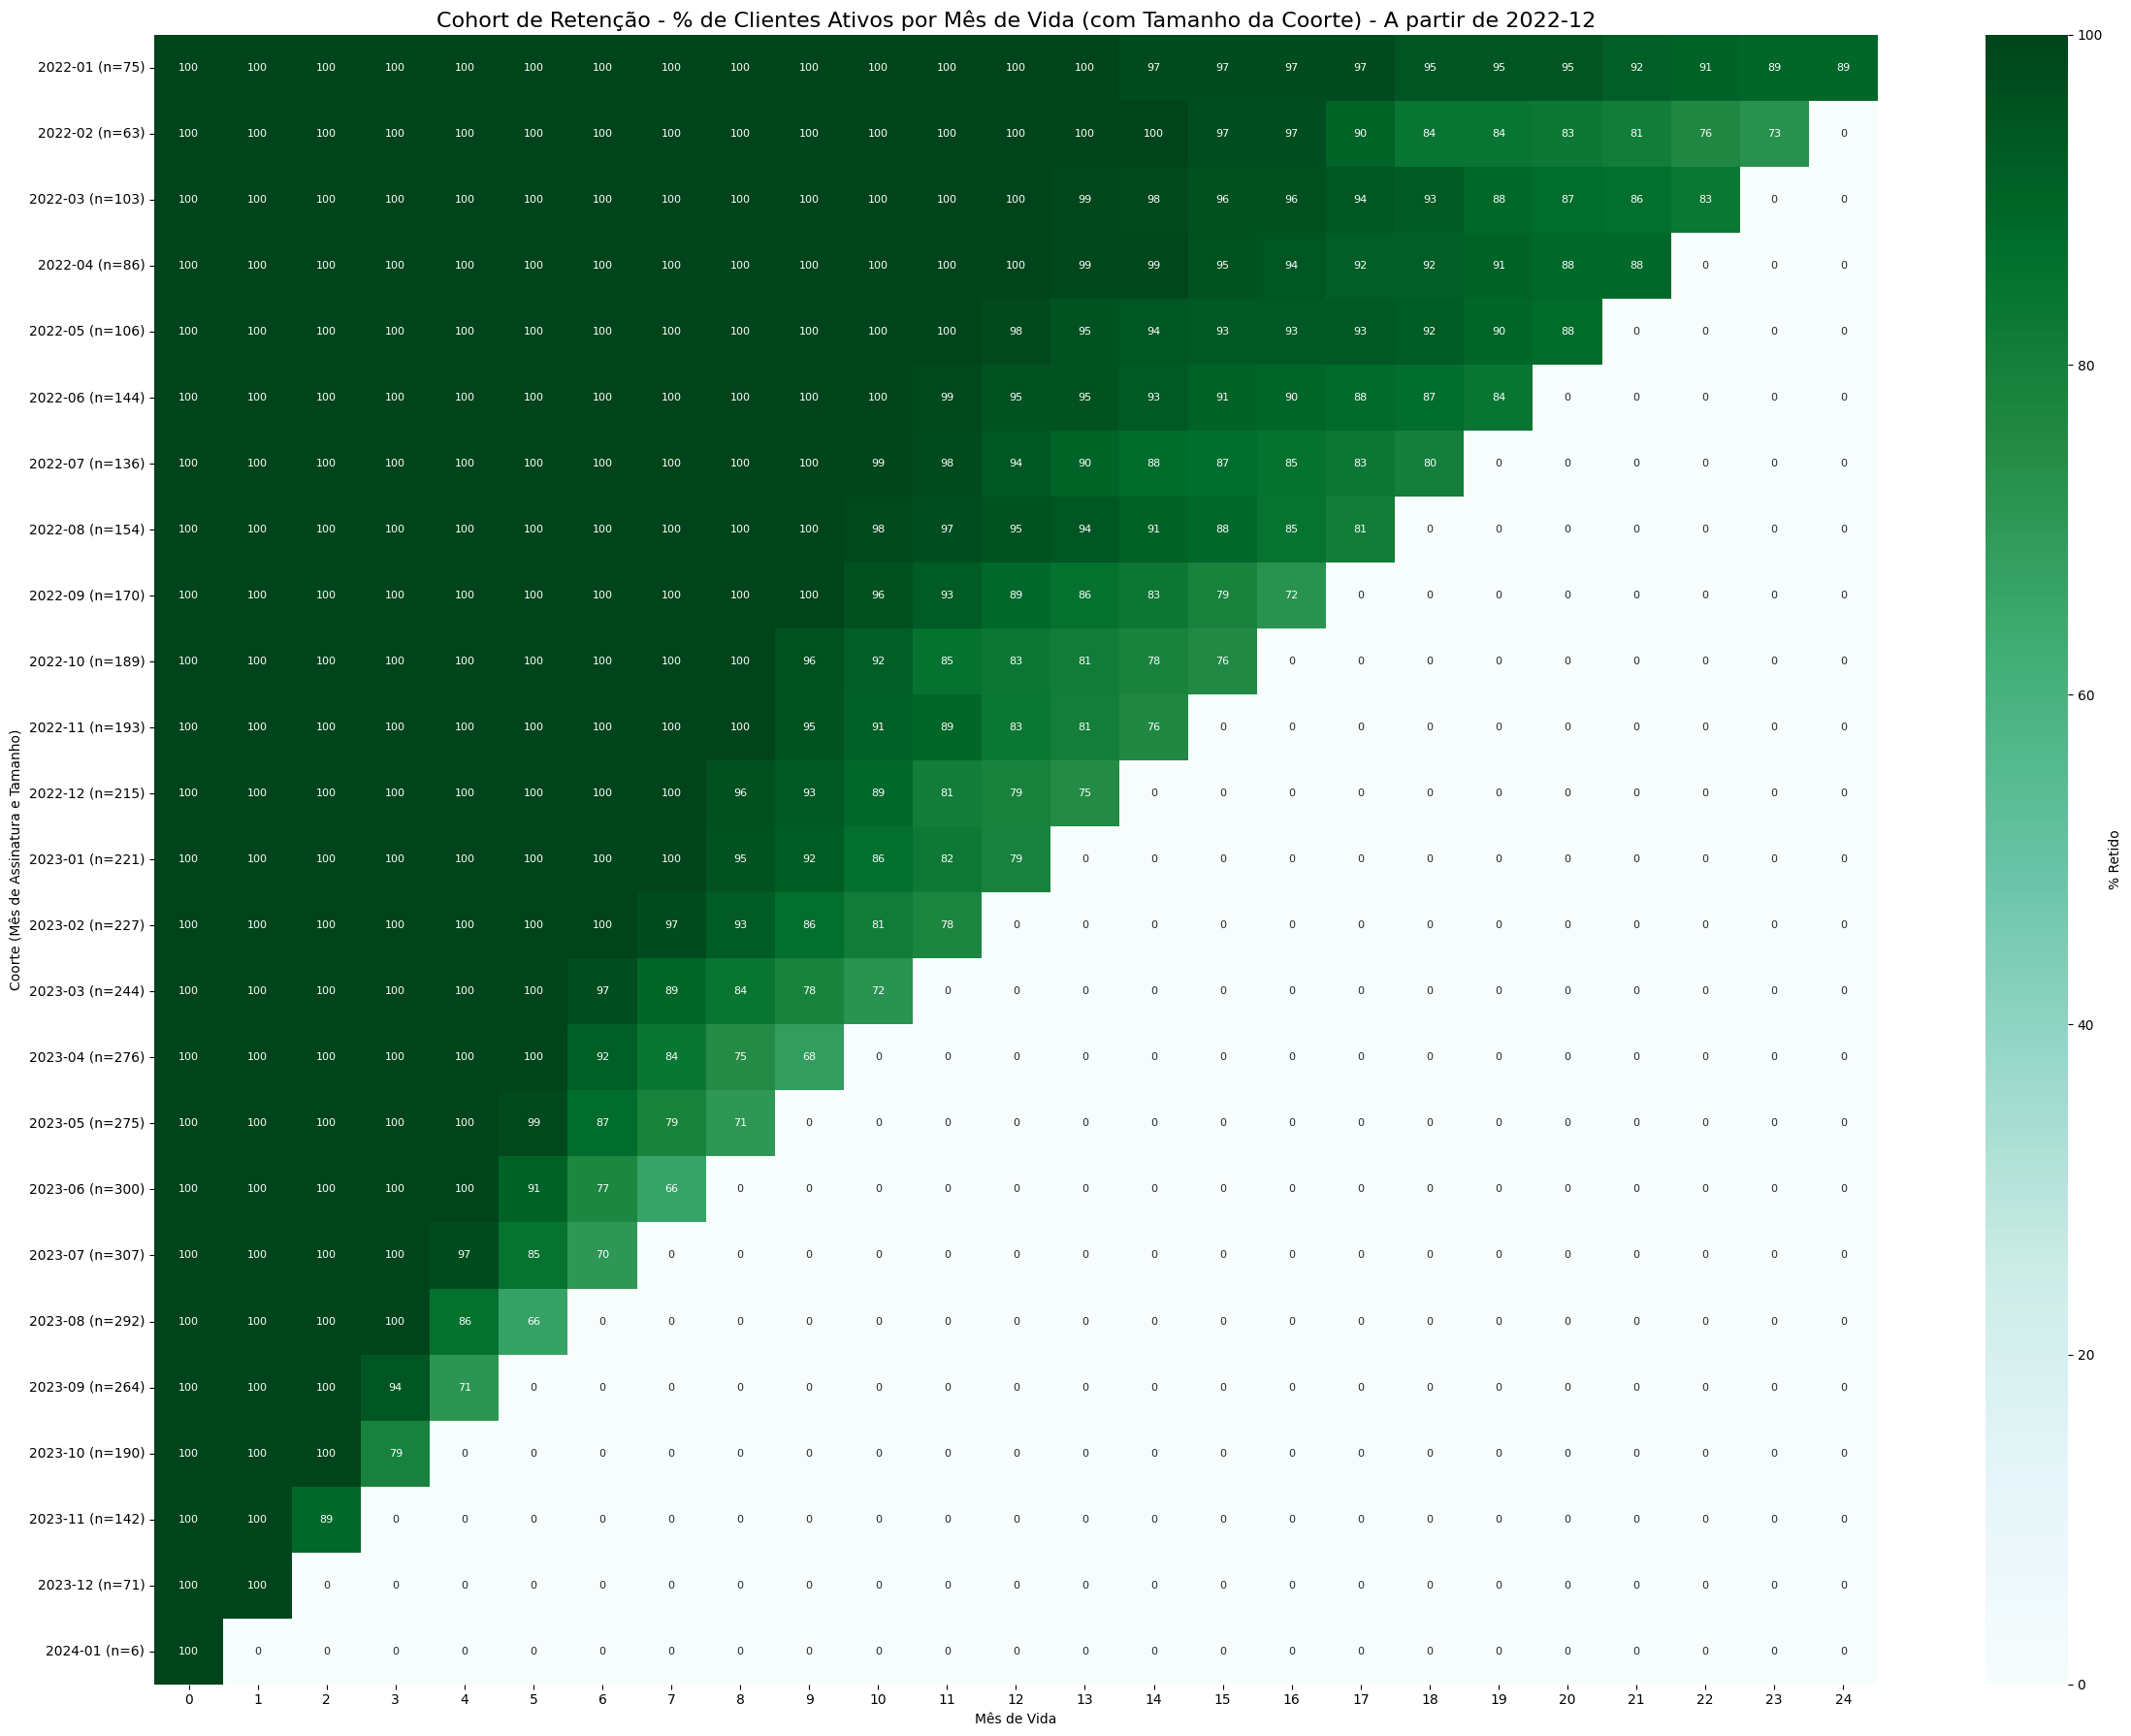

In [ ]:
# Criar uma cópia para evitar modificar o DataFrame original `df_filtrado` diretamente
cohort_analysis_df = df_filtrado.copy()

# 1. Definir o 'fim da permanência' para cada cliente
# Se 'data_cancelamento' for nula, o cliente ainda está ativo, então usamos 'data_extracao'.
# Caso contrário, usamos 'data_cancelamento'.
cohort_analysis_df['fim_permanencia'] = cohort_analysis_df['data_cancelamento'].fillna(cohort_analysis_df['data_extracao'])

# 2. Definir a coorte de entrada (mês e ano da data de assinatura)
# Convertemos para Period('M') para facilitar comparações e cálculos de diferença de meses.
cohort_analysis_df['coorte'] = cohort_analysis_df['data_assinatura'].dt.to_period('M')

# 3. Calcular a duração da permanência em meses (meses_permanencia_total)
# A diferença é calculada entre o mês de fim_permanencia e o mês da coorte.
# A função .n de PeriodDtype representa o número de meses desde a época.
cohort_analysis_df['meses_permanencia_total'] = (
    cohort_analysis_df['fim_permanencia'].dt.to_period('M').astype(int) -
    cohort_analysis_df['coorte'].astype(int)
).clip(lower=0)

# 4. Expandir os dados para que cada cliente apareça em todos os 'meses de vida' em que esteve ativo
expanded_data = []
for idx, row in cohort_analysis_df.iterrows():
    for mes_de_vida in range(row['meses_permanencia_total'] + 1):
        expanded_data.append({
            'cliente_id': row['cliente_id'],
            'coorte': row['coorte'],
            'mes_de_vida': mes_de_vida
        })

# Criar um novo DataFrame a partir dos dados expandidos
expanded_df = pd.DataFrame(expanded_data)

# 5. Montar a matriz de cohort: cada linha é uma coorte, cada coluna é o mês de vida,
# e o valor é a quantidade de clientes únicos ainda ativos naquele mês.
cohort_counts = expanded_df.groupby(['coorte', 'mes_de_vida'])['cliente_id'].nunique().unstack(fill_value=0)

# 6. Converter a contagem em porcentagem de retenção
# Dividir cada linha pelo número de clientes do 'mes_de_vida' 0 (tamanho original da coorte).
cohort_sizes = cohort_counts.iloc[:, 0] # Número de clientes no mês de vida 0 para cada coorte
retention_matrix = cohort_counts.divide(cohort_sizes, axis=0) * 100

# Formatar o índice da coorte para exibição (Ano-Mês)
retention_matrix.index = retention_matrix.index.strftime('%Y-%m')


# --- Visualização: Heatmap com as especificações do usuário ---

# 1. Filtrar as safras a partir de '2022-12'
retention_matrix_filtered_cohorts = retention_matrix[retention_matrix.index >= '2022-01']

# 2. Limitar aos primeiros 25 meses de vida (colunas 0 a 24)
retention_matrix_filtered = retention_matrix_filtered_cohorts.iloc[:, :25] # do mes 0 ao 24 são 25 colunas

# 3. Preparar os rótulos do eixo Y com o tamanho da coorte
y_labels = [f'{coorte_str} (n={cohort_sizes[pd.Period(coorte_str)]})'
            for coorte_str in retention_matrix_filtered.index]

# 4. Plotar o heatmap
plt.figure(figsize=(24, 18)) # Aumentar o tamanho para acomodar rótulos e números
sns.heatmap(
    retention_matrix_filtered,
    annot=True, # Mostrar números nas células
    fmt=".0f",  # Formatar números sem casas decimais
    cmap='BuGn', # Mapa de cores
    vmin=0, vmax=100, # Escala de cor de 0 a 100%
    cbar_kws={'label': '% Retido'},
    yticklabels=y_labels, # Usar os rótulos customizados para o eixo Y
    annot_kws={"size": 8} # Tamanho da fonte para os números dentro das células
)
plt.title('Cohort de Retenção - % de Clientes Ativos por Mês de Vida (com Tamanho da Coorte) - A partir de 2022-12', fontsize=16)
plt.xlabel('Mês de Vida')
plt.ylabel('Coorte (Mês de Assinatura e Tamanho)')
plt.tight_layout()
plt.show()

- Há **indício de que a retenção piorou nas safras recentes** — as curvas de 2023 caem visivelmente mais rápido que as de 2022, que caem mais rápido que as de 2021. Isso é um sinal de negócio importante: a qualidade da aquisição ou a experiência do produto pode estar se deteriorando.

,mes_de_vida,churns,clientes_em_risco,taxa_churn_%
0,0,0,5011,0.00
1,1,1,4991,0.02
2,2,2,4878,0.04
3,3,4,4680,0.09
4,4,5,4418,0.11
5,5,3,4089,0.07
6,6,2,3774,0.05
7,7,4,3469,0.12
8,8,4,3190,0.13
9,9,8,2945,0.27


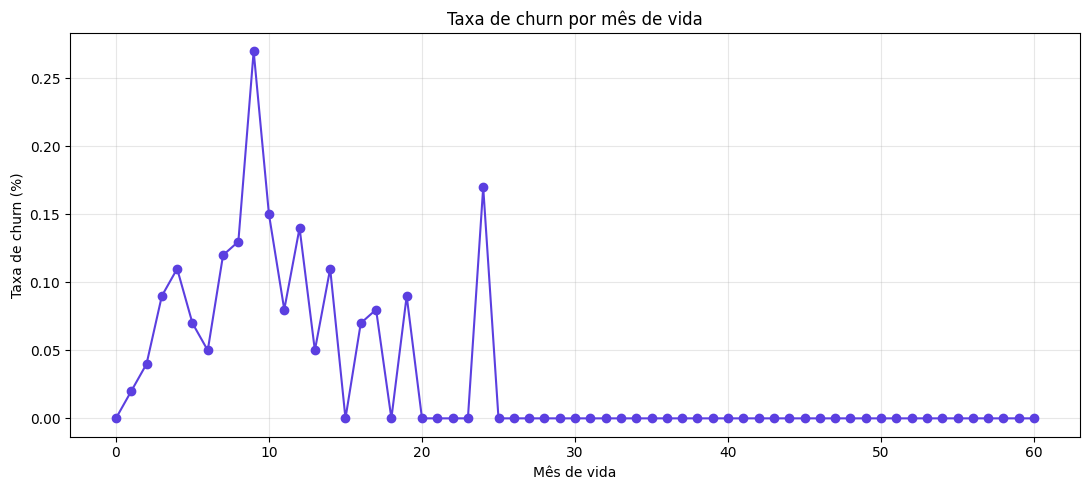

O risco de churn é maior no mês de vida 9 (0.27%).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Taxa de churn por mês de vida ---
# Denominador: clientes que ALCANÇARAM o mês X (meses_assinatura >= X)
# Numerador: clientes que deram churn EXATAMENTE no mês X

max_mes = int(df_filtrado['meses_assinatura'].max())

linhas = []
for x in range(0, max_mes + 1):
    em_risco = (df_filtrado['meses_assinatura'] >= x).sum()
    churns = ((df_filtrado['churn'] == 1) & (df_filtrado['meses_assinatura'] == x)).sum()
    taxa = (churns / em_risco * 100) if em_risco > 0 else np.nan
    linhas.append({'mes_de_vida': x, 'churns': churns,
                   'clientes_em_risco': em_risco, 'taxa_churn_%': round(taxa, 2)})

tabela_taxa = pd.DataFrame(linhas)
display(tabela_taxa.head(20))

# --- Gráfico ---
plt.figure(figsize=(11, 5))
plt.plot(tabela_taxa['mes_de_vida'], tabela_taxa['taxa_churn_%'],
         marker='o', color='#5B3FE0')
plt.title('Taxa de churn por mês de vida')
plt.xlabel('Mês de vida')
plt.ylabel('Taxa de churn (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Conclusão automática ---
pico = tabela_taxa.loc[tabela_taxa['taxa_churn_%'].idxmax()]
print(f"O risco de churn é maior no mês de vida {int(pico['mes_de_vida'])} "
      f"({pico['taxa_churn_%']}%).")

## Framework 2 — RFM adaptado a streaming

Queremos segmentar todos os clientes para ação, inclusive os novos. Como aqui não há compra repetida, adaptamos:

- **Recência** = `recencia` (dias desde o último acesso — menor é melhor)
- **Frequência** = `dias_ativos_ult_mes` (uso — maior é melhor)
- **Monetário** = `valor_mensal` (valor do plano — maior é melhor)


> Nota: `dias_ativos` e `recencia` são contaminadas para *prever* churn, mas aqui o uso é diferente — estamos **descrevendo e segmentando** o estado atual do cliente para ação, não prevendo o desfecho. Nesse contexto, medir engajamento é legítimo.

Removidas 35 linhas com 'recencia' nula.

Quintis para Recência:


,min,max
R,,
5,0.0,6.0
4,7.0,11.0
3,12.0,17.0
2,18.0,23.0
1,24.0,29.0



Quintis para Frequência (dias_ativos_ult_mes):


,min,max
F,,
1,3,11
2,11,13
3,13,15
4,15,17
5,17,28



Quintis para Monetário (valor_mensal):


...


Exemplo de RFM Score:


,cliente_id,R,F,M,RFM_Score
0,5746,5,3,1,531
1,4100,5,3,2,532
3,3454,2,5,1,251
4,1437,3,1,1,311
5,1521,4,1,4,414



Distribuição de Segmentos (Contagem e Porcentagem):


,Contagem,Porcentagem
segmento,,
Regulares,979,28.25
Em risco,813,23.46
Engajados,569,16.42
Adormecidos,556,16.05
Novos/Ativos recentes,548,15.82


/tmp/ipykernel_5702/2539787493.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segmento_counts.values, y=segmento_counts.index, palette='viridis')


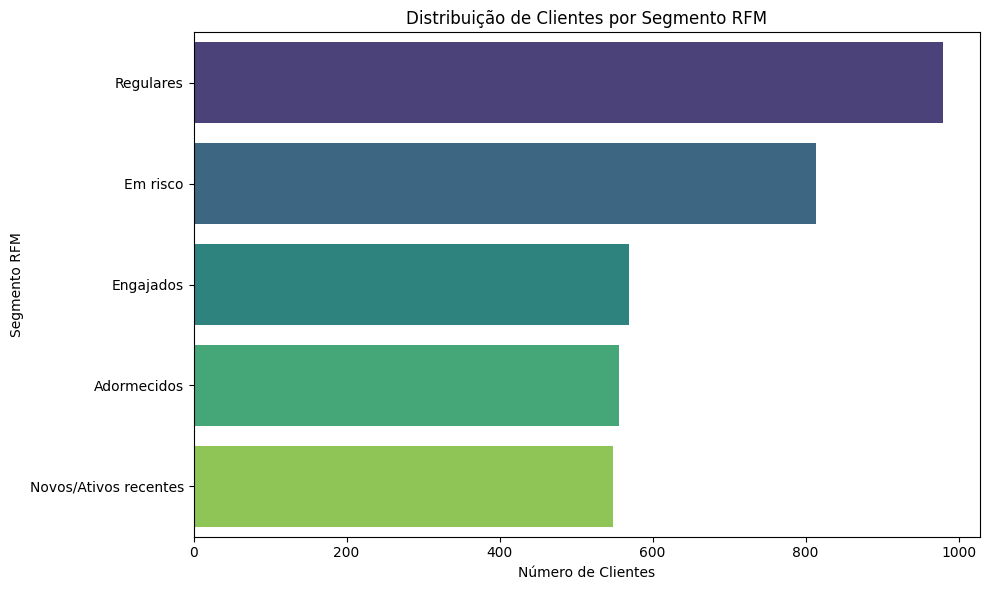

In [ ]:
rfm = df_filtrado[df_filtrado['churn'] == 0].copy()

# 1. Tratar nulos na recencia: remover linhas com valores nulos na coluna 'recencia'
initial_rfm_rows = len(rfm)
rfm.dropna(subset=['recencia'], inplace=True)
print(f"Removidas {initial_rfm_rows - len(rfm)} linhas com 'recencia' nula.")

# Atribua notas de 1 a 5 para cada dimensão usando quintis.
# Atenção à direção: na recência, a nota 5 vai para os menores valores (mais recente = melhor),
# então inverta os rótulos dela. Na frequência e no monetário, a nota 5 vai para os maiores valores.

# Recência (menor é melhor -> nota 5 para menores valores)
rfm['R'] = pd.qcut(rfm['recencia'], 5, labels=[5, 4, 3, 2, 1], duplicates='drop').astype(int)

# Frequência (maior é melhor -> nota 5 para maiores valores)
rfm['F'] = pd.qcut(rfm['dias_ativos_ult_mes'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Monetário (maior é melhor -> nota 5 para maiores valores)
rfm['M'] = pd.qcut(rfm['valor_mensal'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

print("\nQuintis para Recência:")
display(rfm.groupby('R')['recencia'].agg(['min', 'max']).sort_index(ascending=False))

print("\nQuintis para Frequência (dias_ativos_ult_mes):")
display(rfm.groupby('F')['dias_ativos_ult_mes'].agg(['min', 'max']))

print("\nQuintis para Monetário (valor_mensal):")
display(rfm.groupby('M')['valor_mensal'].agg(['min', 'max']))

# Terceiro, crie uma coluna com o código RFM concatenando as três notas
rfm['RFM_Score'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)
print("\nExemplo de RFM Score:")
display(rfm[['cliente_id', 'R', 'F', 'M', 'RFM_Score']].head())

# Quarto, classifique cada cliente num segmento com nome claro, usando as notas R e F como base
def segmento(row):
    if row['R'] >= 4 and row['F'] >= 4:
        return 'Engajados'
    elif row['R'] <= 2 and row['F'] >= 3:
        return 'Em risco'
    elif row['R'] >= 4 and row['F'] <= 2:
        return 'Novos/Ativos recentes'
    elif row['R'] <= 2 and row['F'] <= 2:
        return 'Adormecidos'
    else:
        return 'Regulares'

rfm['segmento'] = rfm.apply(segmento, axis=1)

# Quinto, mostre quantos clientes há em cada segmento (contagem e porcentagem)
print("\nDistribuição de Segmentos (Contagem e Porcentagem):")
segmento_counts = rfm['segmento'].value_counts()
segmento_percentages = rfm['segmento'].value_counts(normalize=True) * 100
segmento_df = pd.DataFrame({'Contagem': segmento_counts, 'Porcentagem': segmento_percentages.round(2)})
display(segmento_df)

# Plotar um gráfico de barras horizontais com o tamanho de cada segmento
plt.figure(figsize=(10, 6))
sns.barplot(x=segmento_counts.values, y=segmento_counts.index, palette='viridis')
plt.title('Distribuição de Clientes por Segmento RFM')
plt.xlabel('Número de Clientes')
plt.ylabel('Segmento RFM')
plt.tight_layout()
plt.show()


## Framework 3 — Pareto dos motivos de cancelamento

Filtra `churn == 1` por natureza (só quem cancelou tem motivo). Base completa: queremos entender **todas** as causas de saída, não só as dos maduros.

In [ ]:
import pandas as pd
import numpy as np
import unicodedata
import matplotlib.pyplot as plt

def normalizar_texto(texto):
    if pd.isna(texto):
        return np.nan
    # Convertendo para string, minúsculo e removendo espaços adicionais
    texto = str(texto).strip().lower()
    # Removendo acentos de forma correta
    texto_normalizado = unicodedata.normalize('NFKD', texto)
    return "".join(c for c in texto_normalizado if not unicodedata.combining(c))

# Criando uma cópia do DataFrame filtrado para garantir integridade
df_pareto = df_filtrado.copy()

# Aplicando a normalização na coluna motivo_cancelamento
df_pareto['motivo_cancelamento_norm'] = df_pareto['motivo_cancelamento'].apply(normalizar_texto)

# Filtrando apenas os registros não nulos para a contagem
contagem_motivos = df_pareto['motivo_cancelamento_norm'].dropna().value_counts().reset_index()
contagem_motivos.columns = ['Motivo', 'Quantidade']

# Calculando as porcentagens para a análise de Pareto
total_cancelamentos = contagem_motivos['Quantidade'].sum()
contagem_motivos['Porcentagem (%)'] = (contagem_motivos['Quantidade'] / total_cancelamentos) * 100
contagem_motivos['Porcentagem Acumulada (%)'] = contagem_motivos['Porcentagem (%)'].cumsum()

print("=== Tabela de Pareto dos Motivos de Cancelamento ===")
display(contagem_motivos)

# Identificando os motivos que concentram cerca de 80%
motivos_80 = contagem_motivos[contagem_motivos['Porcentagem Acumulada (%)'] <= 85] # margem para pegar os que chegam perto de 80%
print("\n=== Motivos que representam a maior parte dos cancelamentos (até ~80% acumulado) ===")
display(motivos_80)

=== Tabela de Pareto dos Motivos de Cancelamento ===


,Motivo,Quantidade,Porcentagem (%),Porcentagem Acumulada (%)
0,preco,507,33.553938,33.553938
1,pouco conteudo novo,384,25.413633,58.967571
2,problema tecnico,249,16.479153,75.446724
3,falta de tempo,174,11.515553,86.962277
4,concorrente,130,8.603574,95.565850
5,outro,67,4.434150,100.000000



=== Motivos que representam a maior parte dos cancelamentos (até ~80% acumulado) ===


,Motivo,Quantidade,Porcentagem (%),Porcentagem Acumulada (%)
0,preco,507,33.553938,33.553938
1,pouco conteudo novo,384,25.413633,58.967571
2,problema tecnico,249,16.479153,75.446724


/tmp/ipykernel_5702/2282232445.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(contagem_motivos['Motivo'], rotation=45, ha='right')


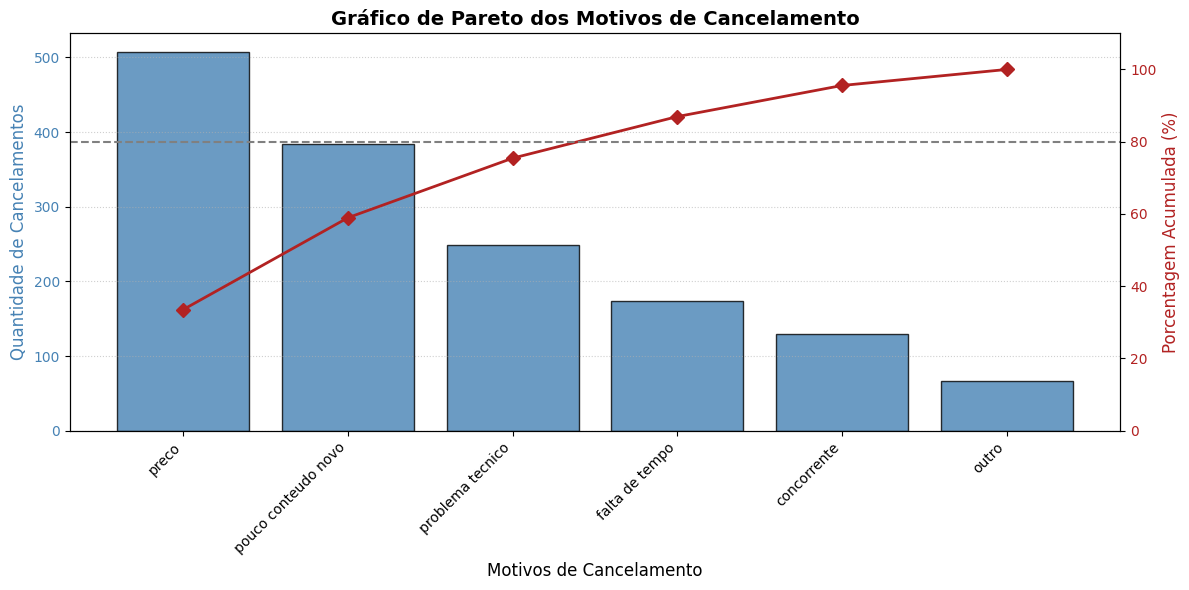

In [ ]:
# Gerando o Gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 6))

# Gráfico de barras para as quantidades (eixo Y esquerdo)
ax1.bar(contagem_motivos['Motivo'], contagem_motivos['Quantidade'], color='steelblue', alpha=0.8, edgecolor='black')
ax1.set_xlabel('Motivos de Cancelamento', fontsize=12)
ax1.set_ylabel('Quantidade de Cancelamentos', color='steelblue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_xticklabels(contagem_motivos['Motivo'], rotation=45, ha='right')

# Criando um segundo eixo Y para a linha de porcentagem acumulada (eixo Y direito)
ax2 = ax1.twinx()
ax2.plot(contagem_motivos['Motivo'], contagem_motivos['Porcentagem Acumulada (%)'], color='firebrick', marker='D', ms=7, linestyle='-', linewidth=2)
ax2.set_ylabel('Porcentagem Acumulada (%)', color='firebrick', fontsize=12)
ax2.tick_params(axis='y', labelcolor='firebrick')
ax2.set_ylim(0, 110)

# Linha horizontal de corte em 80%
ax2.axhline(y=80, color='gray', linestyle='--', linewidth=1.5, label='Linha de Referência (80%)')

plt.title('Gráfico de Pareto dos Motivos de Cancelamento', fontsize=14, fontweight='bold')
ax1.grid(True, axis='y', linestyle=':', alpha=0.6)
fig.tight_layout()
plt.show()

## Framework 4 — Funil de onboarding

Usa um dataset próprio (`funil_eventos.csv`), com uma linha por evento de cada cliente. Independe dos outros frameworks.

In [ ]:
import os
import pandas as pd

# Caminho para o arquivo funil_eventos.csv baseado no diretório anterior
funil_csv_path = os.path.join(pasta_path, 'funil_eventos.csv')

# Carregando o DataFrame
df_funil = pd.read_csv(funil_csv_path)

# Exibindo o tamanho antes da remoção de duplicados
tamanho_antes = df_funil.shape[0]

# Removendo linhas duplicadas
df_funil = df_funil.drop_duplicates()
tamanho_depois = df_funil.shape[0]

print(f"Quantidade de registros antes de remover duplicadas: {tamanho_antes}")
print(f"Quantidade de registros após remover duplicadas: {tamanho_depois}")
print(f"Duplicadas removidas: {tamanho_antes - tamanho_depois}\n")

# Exibindo as primeiras linhas
display(df_funil.head())

Quantidade de registros antes de remover duplicadas: 12886
Quantidade de registros após remover duplicadas: 12836
Duplicadas removidas: 50



,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula


In [ ]:
# 1. Padronizando a coluna etapa
df_funil['etapa'] = df_funil['etapa'].str.strip().str.lower().str.replace(' ', '_')

# Exibindo os valores únicos após a padronização para verificar
print("Etapas unificadas:")
print(df_funil['etapa'].value_counts())


Etapas unificadas:
etapa
visitou_site        5000
criou_conta         3377
assistiu_1a_aula    2698
assinou_plano       1066
renovou              695
Name: count, dtype: int64


In [ ]:
# 2. Contando clientes únicos por etapa na ordem correta do funil
ordem_funil = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou_plano', 'renovou']

# Calculamos o número de usuários únicos em cada etapa
clientes_etapa = {}
for etapa in ordem_funil:
    # Para garantir o comportamento de funil acumulado onde um usuário na etapa N também passou pelas anteriores,
    # ou simplesmente contando quantos únicos registraram o evento daquela etapa:
    clientes_etapa[etapa] = df_funil[df_funil['etapa'] == etapa]['cliente_id'].nunique()

# Criando o DataFrame do funil
df_resultados_funil = pd.DataFrame(list(clientes_etapa.items()), columns=['Etapa', 'Clientes Únicos'])

# 3. Calculando as taxas de conversão
df_resultados_funil['Conversão vs Anterior (%)'] = 100.0
df_resultados_funil['Conversão vs Topo (%)'] = 100.0

topo_funil_valor = df_resultados_funil.loc[0, 'Clientes Únicos']

for i in range(len(df_resultados_funil)):
    # Conversão em relação ao topo
    df_resultados_funil.loc[i, 'Conversão vs Topo (%)'] = (df_resultados_funil.loc[i, 'Clientes Únicos'] / topo_funil_valor) * 100

    # Conversão em relação à etapa anterior
    if i > 0:
        anterior_valor = df_resultados_funil.loc[i-1, 'Clientes Únicos']
        df_resultados_funil.loc[i, 'Conversão vs Anterior (%)'] = (df_resultados_funil.loc[i, 'Clientes Únicos'] / anterior_valor) * 100
    else:
        df_resultados_funil.loc[i, 'Conversão vs Anterior (%)'] = 100.0

print("=== Tabela do Funil de Conversão ===")
display(df_resultados_funil)



=== Tabela do Funil de Conversão ===


,Etapa,Clientes Únicos,Conversão vs Anterior (%),Conversão vs Topo (%)
0,visitou_site,5000,100.000000,100.00
1,criou_conta,3377,67.540000,67.54
2,assistiu_1a_aula,2698,79.893397,53.96
3,assinou_plano,1066,39.510749,21.32
4,renovou,695,65.196998,13.90


In [ ]:
# 4. Identificando a etapa com a maior queda de conversão (maior gargalo)
# O gargalo é a etapa (a partir da segunda) que possui a menor taxa de conversão em relação à anterior
gargalo_idx = df_resultados_funil.iloc[1:]['Conversão vs Anterior (%)'].idxmin()
etapa_gargalo = df_resultados_funil.loc[gargalo_idx, 'Etapa']
queda_gargalo = df_resultados_funil.loc[gargalo_idx, 'Conversão vs Anterior (%)']

print(f"O maior gargalo do funil é a etapa '{etapa_gargalo}', onde apenas {queda_gargalo:.2f}% dos usuários da etapa anterior avançaram.")


O maior gargalo do funil é a etapa 'assinou_plano', onde apenas 39.51% dos usuários da etapa anterior avançaram.


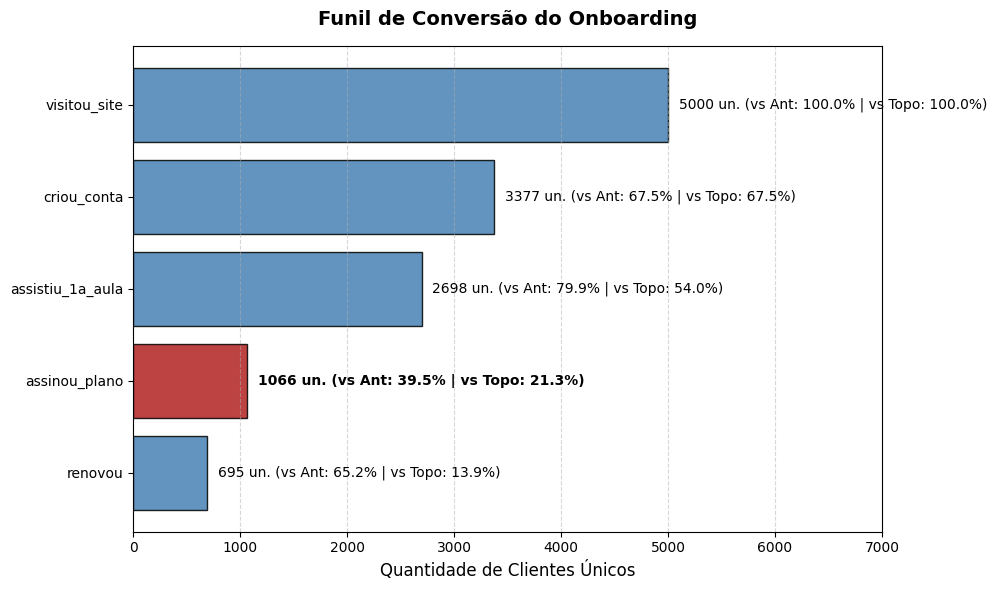

In [ ]:
import matplotlib.pyplot as plt

# 5. Plotando o gráfico de barras horizontais do Funil
plt.figure(figsize=(10, 6))

# Definindo cores: vermelho para o gargalo, azul aço para as demais
cores = ['steelblue' if etapa != etapa_gargalo else 'firebrick' for etapa in df_resultados_funil['Etapa']]

# Invertendo a ordem para o topo do funil aparecer acima
df_plot = df_resultados_funil.iloc[::-1]
cores_plot = cores[::-1]

bars = plt.barh(df_plot['Etapa'], df_plot['Clientes Únicos'], color=cores_plot, edgecolor='black', alpha=0.85)

# Adicionando rótulos com a quantidade e as taxas de conversão nas barras
for bar, total, conv_ant, conv_topo in zip(bars, df_plot['Clientes Únicos'], df_plot['Conversão vs Anterior (%)'], df_plot['Conversão vs Topo (%)']):
    plt.text(
        bar.get_width() + (max(df_plot['Clientes Únicos']) * 0.02),
        bar.get_y() + bar.get_height()/2,
        f"{total} un. (vs Ant: {conv_ant:.1f}% | vs Topo: {conv_topo:.1f}%)",
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold' if bar.get_facecolor() == (178/255, 34/255, 34/255, 0.85) else 'normal' # destaca texto do gargalo
    )

plt.title('Funil de Conversão do Onboarding', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade de Clientes Únicos', fontsize=12)
plt.xlim(0, max(df_plot['Clientes Únicos']) * 1.4) # Espaço para os rótulos de texto
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()